# · Assignment 5 · Retrieval-Augmented Generation (RAG) Chatbot


This notebook builds an AI assistant that answers questions about the **EDAB 6808 Learner Guide**, and only the learner guide.
Every answer shows the guide page and section it came from, and the assistant refuses questions the guide does not support.

### Pipeline at a glance

```
Learner Guide PDF
   │  1. PyMuPDF extraction  →  remove footers / artefacts  →  inspect
   ▼
Clean pages ──► 2. section-aware, sentence-aware chunks (≈200 tokens, stable IDs, page + section metadata)
   │
   ▼  3. BAAI/bge-small-en-v1.5 (open-weight, 384-d)
Vectors ──► 4. Qdrant Local collection on Google Drive (vector + text + metadata payload)
   │
   ▼  5. Dense top-20  +  BM25 top-20  →  Reciprocal Rank Fusion  →  cross-encoder rerank  →  top k = 4
Evidence ──► relevance gate + strongest-passage filter (abstain if evidence is weak)
   │
   ▼  6. Qwen2.5-3B-Instruct, evidence-only prompt, greedy decoding
Answer ──► 7. citations verified against the evidence text and built from stored metadata (page · section · chunk ID),
   │            faithfulness check on every statement  /  explicit abstention
   │
   ▼  8. 20-question evaluation (Hit@k, MRR, context precision/recall, answer / citation accuracy, faithfulness, abstention, latency)
   ▼  9. Gradio chat interface with the 20 questions as clickable demonstrations
```

### How to run
1. **Runtime → Change runtime type → T4 GPU.**
2. Put the learner guide PDF in `MyDrive/EDAB6808_RAG/` (or upload it when the notebook asks).
3. **Runtime → Run all.** The Qdrant collection is saved on Drive, so later runs reuse it instead of re-indexing.

| Assignment requirement | Notebook section |
|---|---|
| 1. Source ingestion & text extraction | §1 |
| 2. Chunking & source metadata (size justified, loss check, trade-off) | §2 |
| 3. Open-weight embeddings (model + dimension) | §3 |
| 4. Qdrant vector database (payload, count check, rerun-safe, Drive persistence) | §4 |
| 5. Retrieval + relevance improvement (k justified, BM25 + RRF + reranker, explainability) | §5 |
| 6. Grounded generation with Qwen | §6 |
| 7. Citations (verified), faithfulness check & abstention | §7, §7a |
| 8. Evaluation (20 questions, 9 guide sections, summary metrics) | §8 |
| 9. Chatbot interface | §9 |

## 0. Setup
Run the cells in order on a Google Colab T4 GPU runtime. Setup downloads three open-weight models from Hugging Face (the embedding model, the reranker and Qwen); no hosted generation API is used.

In [ ]:
%pip install -q "pymupdf==1.26.5" "qdrant-client==1.15.1" "sentence-transformers==5.1.1" "transformers==4.57.1" "rank-bm25==0.2.2" "gradio==5.49.1" "accelerate==1.11.0"
# If Colab asks you to restart the runtime after the installation, restart it and continue from the next cell.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.1/24.1 MB 86.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 337.3/337.3 kB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 486.6/486.6 kB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 123.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.5/63.5 MB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 375.8/375.8 kB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.4/325.4 kB 34.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 444.8/444.8 kB 41.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 71.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
# ---------------------------------------------------------------------------
# Imports and global configuration
# ---------------------------------------------------------------------------
import os, re, json, time, uuid, shutil, hashlib, unicodedata, textwrap
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 120)   # show longer text in DataFrames
torch.manual_seed(42); np.random.seed(42)    # reproducibility (generation is greedy anyway)

# ---- Hardware -------------------------------------------------------------
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
DTYPE  = torch.float16 if DEVICE == "cuda" else torch.float32   # half precision halves GPU memory
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))

# ---- Storage: persist everything on Google Drive ---------------------------
# Persisting the Qdrant collection on Drive means the index survives a Colab
# disconnect and is ready before the presentation without rebuilding.
USE_DRIVE = True
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:          # lets the notebook also run locally / in Jupyter
    IN_COLAB = False

if USE_DRIVE and IN_COLAB:
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/EDAB6808_RAG"
else:
    PROJECT_DIR = os.path.abspath("EDAB6808_RAG")
os.makedirs(PROJECT_DIR, exist_ok=True)

PDF_PATH        = os.path.join(PROJECT_DIR, "Learner_Guide_EDAB6808_.pdf")   # the ONLY knowledge source
QDRANT_PATH     = os.path.join(PROJECT_DIR, "qdrant_db")                   # Qdrant Local storage folder
INDEX_META_PATH = os.path.join(PROJECT_DIR, "index_fingerprint.json")      # used to detect stale indexes
COLLECTION      = "edab6808_learner_guide"

# ---- Models (all open-weight, all run locally) -----------------------------
EMBED_MODEL_NAME  = "BAAI/bge-small-en-v1.5"                 # SentenceTransformers embedding model, 384-d
RERANK_MODEL_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"   # cross-encoder reranker (22M params, fast)
LLM_NAME          = "Qwen/Qwen2.5-3B-Instruct"               # instruction-tuned Qwen; ~6 GB in fp16 on a T4
# CPU / low-memory fallback: "Qwen/Qwen2.5-1.5B-Instruct" or "Qwen/Qwen2.5-0.5B-Instruct"

# ---- Chunking ---------------------------------------------------------------
CHUNK_MAX_TOKENS        = 200   # justified in §2 and tested in §3
CHUNK_OVERLAP_SENTENCES = 1     # carry one sentence into the next chunk so ideas are not cut mid-thought

# ---- Retrieval ---------------------------------------------------------------
DENSE_CANDIDATES = 20   # how many chunks Qdrant returns before fusion
BM25_CANDIDATES  = 20   # how many chunks BM25 returns before fusion
RRF_K            = 60   # standard Reciprocal Rank Fusion constant (Cormack et al., 2009)
RERANK_POOL      = 15   # fused candidates scored by the cross-encoder
FINAL_K          = 4    # evidence chunks passed to the LLM (justified in §5)
EVIDENCE_MIN_RATIO = 0.10  # a chunk is passed to the LLM only if its score >= 10% of the best chunk's score
CITE_MIN_FIRST   = 0.30  # citation verification: a passage is cited if it contains >= 30% of a statement's weighted key terms
CITE_MIN_GAIN    = 0.12  # ... and a further passage is added only if it contributes >= 12% more
CITE_LABEL_BONUS = 0.05  # the model's own label only breaks ties
FAITH_LEX_THR    = 0.60  # faithfulness: share of a statement's weighted key terms that must appear in the evidence
RETRIEVAL_GATE   = 0.10 # minimum reranker score to attempt an answer; re-calibrated in §5

# ---- Generation --------------------------------------------------------------
MAX_NEW_TOKENS = 320    # enough for a 1-5 sentence answer with citations
# Retrieval models run on CPU to leave GPU memory for Qwen.
RETRIEVAL_DEVICE = "cpu"
LAUNCH_UI = True
SHARE_UI = IN_COLAB  # temporary Gradio presentation link in Colab

print("Generation model:", LLM_NAME)

Device: cuda (Tesla T4)
Mounted at /content/drive
Generation model: Qwen/Qwen2.5-3B-Instruct


In [ ]:
import fitz  # PyMuPDF
from pathlib import Path

# The learner guide is the ONLY knowledge source. Look for it on Drive, in the working folder, or ask for an upload.
def find_guide():
    for folder in (PROJECT_DIR, os.getcwd(), "/content"):
        for f in sorted(Path(folder).glob("Learner*Guide*EDAB6808*.pdf")):
            return f
    return None

found = find_guide()
if found is None and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    names = [n for n in uploaded if re.search(r"Learner.*Guide.*EDAB6808.*\.pdf$", n, re.I)]
    if not names:
        raise ValueError("Upload the Learner Guide PDF (file name containing 'Learner Guide' and 'EDAB6808').")
    found = Path(names[0])
if found is None:
    raise FileNotFoundError(f"Place the learner guide PDF in {PROJECT_DIR}")
if Path(found).resolve() != Path(PDF_PATH).resolve():
    shutil.copy2(found, PDF_PATH)

with open(PDF_PATH, "rb") as f:
    PDF_SHA = hashlib.sha256(f.read()).hexdigest()
with fitz.open(PDF_PATH) as _d:
    assert "EDAB6808" in _d[0].get_text(), "This does not look like the EDAB6808 learner guide."
    print(f"Only knowledge source: {Path(PDF_PATH).name} ({_d.page_count} pages)")
print(f"SHA256: {PDF_SHA}")

Only knowledge source: Learner_Guide_EDAB6808_.pdf (16 pages)
SHA256: 1f5711c1810192b953a569747049fdb3f0a8c52d417cd72870ace9f5cf367797


## 1. Source ingestion and text extraction

We use **PyMuPDF** for three reasons:
* it returns text **blocks with coordinates**, so we can read the page top-to-bottom (`sort=True`) — without this, the heading
  *“7. Assessment of Learning”* on page 13 is extracted *after* its own paragraph and gets the wrong section label;
* `find_tables()` recovers the **tables** (module schedule, assessment weights, learning units) row by row, so a question such as
  *“What does Assignment 5 count?”* retrieves the row *“Assignment 5 | … | 20%”* instead of numbers scattered across lines;
* it is fast and needs no OCR — the guide is a born-digital PDF.

The goal is to **preserve** the guide, not rewrite it: we only remove page footers and extraction artefacts.
Table detection uses `lines_strict` so that the shaded table cells are not mistaken for extra cell boundaries. Each table row keeps its own chunk boundary, and the extracted rows can be checked in the chunk listing in §2.

In [ ]:
import fitz  # PyMuPDF

doc = fitz.open(PDF_PATH)
print(f"Pages in PDF: {doc.page_count}")

def rect_overlap_ratio(a, b):
    """Share of rectangle a's area that lies inside rectangle b (0..1)."""
    a, b = fitz.Rect(a), fitz.Rect(b)
    inter = a & b                       # PyMuPDF: '&' is rectangle intersection
    if inter.is_empty:
        return 0.0
    return (inter.width * inter.height) / max(a.width * a.height, 1e-6)

def extract_page(page):
    """Return one page as an ordered list of 'items' (text blocks and tables).

    Each item keeps its vertical position (y0) so that tables and paragraphs
    can be interleaved in true reading order.
    """
    height = page.rect.height

    # 1) Detect tables first, so their text is not ALSO extracted as loose lines.
    tables = []
    try:
        for t in page.find_tables(strategy="lines_strict").tables:
            if t.row_count >= 2 and t.col_count >= 2:          # ignore 1-cell "boxes"
                tables.append((fitz.Rect(t.bbox), t.extract()))
    except Exception as e:                                       # older PyMuPDF: no find_tables
        print(f"  page {page.number + 1}: table detection unavailable ({e}); using plain text")

    # 2) Text blocks, sorted top-to-bottom / left-to-right.
    items = []
    # Use individual lines: dropping an entire mixed text/table block can lose prose.
    for block in page.get_text("dict", sort=True)["blocks"]:
        for line in block.get("lines", []):
            rect = fitz.Rect(line["bbox"])
            if any(rect_overlap_ratio(rect, tr) > 0.8 for tr, _ in tables):
                continue
            text = "".join(span["text"] for span in line["spans"]).strip()
            if text:
                items.append({"kind": "text", "y0": rect.y0, "lines": [text],
                              "bottom": rect.y0 > 0.90 * height,
                              "margin": rect.y0 < 0.06 * height or rect.y0 > 0.94 * height})

    # 3) Tables become their own items, positioned where they sit on the page.
    for rect, rows in tables:
        items.append({"kind": "table", "y0": rect.y0, "rows": rows, "bottom": False})

    items.sort(key=lambda it: it["y0"])
    return {"pdf_page": page.number + 1,
            "items": items,
            "raw_text": page.get_text("text", sort=True)}        # kept for the inspection report

raw_pages = [extract_page(p) for p in doc]

# ---- Inspect the raw extraction before doing anything else -----------------
inspect_df = pd.DataFrame([{
    "pdf_page": p["pdf_page"],
    "raw_chars": len(p["raw_text"]),
    "text_blocks": sum(it["kind"] == "text" for it in p["items"]),
    "tables": sum(it["kind"] == "table" for it in p["items"]),
} for p in raw_pages])
display(inspect_df)
print("\n--- Raw text of PDF page 15 (assessment weights table), first 1200 chars ---\n")
print(raw_pages[14]["raw_text"][:1200])

Pages in PDF: 16


,pdf_page,raw_chars,text_blocks,tables
0,1,217,11,0
1,2,1153,18,0
2,3,1752,10,1
3,4,3078,36,0
4,5,2586,32,0
5,6,1997,21,1
6,7,1613,34,0
7,8,1831,37,0
8,9,1679,36,0
9,10,1865,37,0



--- Raw text of PDF page 15 (assessment weights table), first 1200 chars ---

a) The entire module mark (100%), will be based on the continuous assessment of the

    module. If a student misses an assessment opportunity without a valid reason, then the

    student will receive an incomplete for the module. A valid excuse is stipulated by the

    faculty rules, and determined by the UFS policy, not the lecturer. Therefore, rule

    implementation will be on the basis of the UFS rules, and no amount of persuasion will

    convince the lecturer of a different outcome, unless stipulated by the UFS policy. All

    people are created equal, and a fair judgement within the system will be implemented

    for all people, using evidence, and a contextual understanding of the rules and its

    limitations.

b)  If an excuse has been found valid, the student will have an opportunity to follow-up

   and defend the assignment in an oral test. The scope of the oral test will be the same as


In [ ]:
# ---------------------------------------------------------------------------
# Cleaning: remove repeated footers / headers and fix extraction artefacts
# ---------------------------------------------------------------------------
# Footers look like "12 | P a g e" (the guide letter-spaces the word "Page").
FOOTER_RE      = re.compile(r"^\s*(\d{1,3})\s*\|\s*P\s*a\s*g\s*e\s*$", re.I)
FOOTER_BITS_RE = re.compile(r"^\s*(?:\d{1,3}\s*\|?|P\s*a\s*g\s*e)\s*$", re.I)   # footer split over 2 lines

# The PDF contains Cyrillic letters that look identical to Latin ones
# (e.g. the word "оr" on page 4 uses a Cyrillic "о"). They break keyword search,
# so we map them back to Latin. This changes no visible character.
HOMOGLYPHS = str.maketrans({
    "а": "a", "е": "e", "о": "o", "р": "p", "с": "c", "у": "y", "х": "x", "і": "i",
    "А": "A", "В": "B", "Е": "E", "К": "K", "М": "M", "Н": "H", "О": "O", "Р": "P",
    "С": "C", "Т": "T", "Х": "X",
})

def clean_text(s):
    """Normalise one line of text without changing its meaning."""
    s = unicodedata.normalize("NFKC", s)          # ligatures (ﬁ -> fi), non-breaking spaces
    s = s.translate(HOMOGLYPHS)
    s = s.replace("­", "")                   # invisible soft hyphens
    s = re.sub(r"\s*\.{4,}\s*(\d+)\s*$", r" (p. \1)", s)   # TOC dot leaders "....... 12" -> "(p. 12)"
    s = re.sub(r"\.{4,}", " ", s)                 # any other dot leaders
    s = re.sub(r"[ \t]+", " ", s).strip()         # collapse runs of spaces
    return s

def clean_cell(c):
    """Table cells: None -> '', join wrapped lines (keep hyphens of compounds like 'real-world')."""
    if c is None:
        return ""
    c = c.replace("-\n", "-").replace("\n", " ")
    return clean_text(c)

def norm_for_repeat(line):
    """Normalise a line for repeated-header detection: digits -> '#', lower case."""
    return re.sub(r"\d+", "#", clean_text(line).lower())

# ---- Generic repeated-line detection (headers/footers on many pages) ----------
# A short line that appears on at least half of the pages is page furniture, not content.
pages_with_line = Counter()
for p in raw_pages:
    seen = {norm_for_repeat(l) for it in p["items"] if it["kind"] == "text" and it.get("margin", False) for l in it["lines"]}
    pages_with_line.update(seen)
BOILERPLATE = {l for l, n in pages_with_line.items()
               if n >= 0.5 * len(raw_pages) and 3 <= len(l) <= 60}
print("Repeated lines treated as boilerplate:", BOILERPLATE or "none")

def clean_page(p):
    """Return a cleaned copy of a page plus the printed page number found in its footer."""
    page_label, removed, items = None, [], []
    for it in p["items"]:
        if it["kind"] == "table":
            rows = [[clean_cell(c) for c in row] for row in it["rows"]]
            items.append({**it, "rows": rows})
            continue
        kept = []
        for line in it["lines"]:
            m = FOOTER_RE.match(line)
            if m:                                             # "12 | P a g e"
                page_label = int(m.group(1)); removed.append(line); continue
            if it["bottom"] and FOOTER_BITS_RE.match(line):   # footer split into pieces
                digits = re.findall(r"\d+", line)
                if digits: page_label = int(digits[0])
                removed.append(line); continue
            if it.get("margin", False) and norm_for_repeat(line) in BOILERPLATE:
                removed.append(line); continue
            line = clean_text(line)
            if line:
                kept.append(line)
        if kept:
            items.append({**it, "lines": kept})
    # The cover has no footer: printed page = PDF page - 1 (cover = page 0).
    if page_label is None:
        page_label = p["pdf_page"] - 1
    return {"pdf_page": p["pdf_page"], "page_label": page_label, "items": items, "removed": removed}

clean_pages = [clean_page(p) for p in raw_pages]
PAGE_LABEL = {p["pdf_page"]: p["page_label"] for p in clean_pages}   # pdf page -> printed page

def page_text(p):
    """Flatten a cleaned page back to text (used only for inspection and loss checks)."""
    out = []
    for it in p["items"]:
        out += it["lines"] if it["kind"] == "text" else [" | ".join(r) for r in it["rows"]]
    return "\n".join(out)

# ---- Cleaning report -------------------------------------------------------
clean_report = pd.DataFrame([{
    "pdf_page": cp["pdf_page"],
    "printed_page": "cover" if cp["page_label"] == 0 else cp["page_label"],
    "raw_chars": len(rp["raw_text"]),
    "clean_chars": len(page_text(cp)),
    "lines_removed": len(cp["removed"]),
    "removed_examples": "; ".join(cp["removed"][:2]),
} for rp, cp in zip(raw_pages, clean_pages)])
display(clean_report)
print(f"Total characters: raw {clean_report.raw_chars.sum():,} -> clean {clean_report.clean_chars.sum():,} "
      f"(inspect removed lines and the preservation checks below)")
print("\n--- Cleaned PDF page 14 (printed page 13) ---\n")
print(page_text(clean_pages[13])[:1500])

Repeated lines treated as boilerplate: none


,pdf_page,printed_page,raw_chars,clean_chars,lines_removed,removed_examples
0,1,cover,217,159,0,
1,2,1,1153,269,1,1 | P a g e
2,3,2,1752,1431,1,2 | P a g e
3,4,3,3078,2963,1,3 | P a g e
4,5,4,2586,2444,1,4 | P a g e
5,6,5,1997,1761,1,5 | P a g e
6,7,6,1613,1310,1,6 | P a g e
7,8,7,1831,1551,1,7 | P a g e
8,9,8,1679,1413,1,8 | P a g e
9,10,9,1865,1541,1,9 | P a g e


Total characters: raw 31,204 -> clean 25,927 (inspect removed lines and the preservation checks below)

--- Cleaned PDF page 14 (printed page 13) ---

6. LIST OF MATERIALS
There is no prescribed textbook for this module.
For data manipulation:
• https://wesmckinney.com/book/pandas-basics
• https://pandas.pydata.org/pandas-docs/version/1.4.4/pandas.pdf
• https://riptutorial.com/Download/pandas.pdf
For data analysis and machine learning
• https://bedford-computing.co.uk/learning/wp-content/uploads/2015/10/Python-for-Data-Analysis.pdf
• https://github.com/terencetachiona/Python-Data-Science-
Handbook/blob/master/Python%20Data%20Science%20Handbook%20-
%20Jake%20VanderPlas.pdf
• https://library.oapen.org/handle/20.500.12657/61296
• https://www.neusncp.com/static/upload/article/201805111319318907.pdf
• https://greenteapress.com/modsimpy/ModSimPy3.pdf
• https://link.springer.com/book/10.1007/978-3-030-16877-3
• https://python-course.eu/books/bernd_klein_python_and_machine_learning_a4.pdf
7. A

## 2. Chunking and source metadata

### Strategy
1. **Recover the document structure.** Numbered upper-case headings (`7. ASSESSMENT OF LEARNING`) become the *section*;
   `Unit n: …` lines become the *sub-section*. Lines are re-joined into paragraphs and bullets are kept as separate paragraphs.
2. **Split paragraphs into sentences** and table rows into one unit per row (rows carry their column headers, e.g.
   `ASSESSMENT: Assignment 5 | … | CONTRIBUTION TO MODULE MARK (weight): 20%`).
3. **Pack sentences into chunks of at most 200 tokens**, never crossing a section, sub-section or table boundary,
   with a **one-sentence overlap** between consecutive chunks of the same section.
4. Each chunk carries a **stable ID** (`edab6808-p15-01` = PDF page 15, first chunk starting on that page), its text,
   PDF page(s), printed page(s), section and sub-section. For retrieval we embed `section › sub-section + text`
   (`embed_text`); the evidence shown to users is the untouched guide text (`text`).

### Why ~200 tokens?
* The guide is written in short topical paragraphs and bullet groups of roughly 80–200 tokens, so a 200-token chunk usually holds
  **one complete idea** (one unit's objectives, one policy paragraph, one table) — precise enough that a citation points to the right place.
* `bge-small-en-v1.5` reads at most **512 tokens**; 200 tokens plus the section header stays far below that, so nothing is truncated.
* With **k = 4** the LLM receives at most ≈ 800 tokens of evidence — enough context for multi-part questions, small enough to keep a 3B model
  focused and to answer in a few seconds on a T4.
* The trade-off (smaller chunks = sharper retrieval but less context per hit; larger chunks = more context but diluted vectors and
  vaguer citations) is measured in the experiment at the end of §3.

In [ ]:
# ---------------------------------------------------------------------------
# 2a. Recover structure: sections, sub-sections, paragraphs, table rows
# ---------------------------------------------------------------------------
MAIN_HEADING_RE = re.compile(r"^(\d{1,2})\.\s+([A-Z][A-Z&,/\- ]{3,})$")   # "7. ASSESSMENT OF LEARNING"
UNIT_HEADING_RE = re.compile(r"^Unit\s+\d+:\s*[A-Z].{3,80}$")             # "Unit 3: Bayesian Networks ..."
OTHER_SECTIONS    = {"TABLE OF CONTENTS": "Table of Contents"}
OTHER_SUBSECTIONS = {"Additional Module Features"}
BULLET_RE      = re.compile(r"^(?:[•●▪■◦]|o(?=\s)|-(?=\s))\s*")  # •, Word's 'o' sub-bullet, dash
BULLET_ONLY_RE = re.compile(r"^[•●▪■◦o\-]$")                       # bullet glyph on its own line
NUMBERED_RE    = re.compile(r"^(?:\d{1,2}\.|[a-z]\))\s+")                            # "1. Apply..." / "a) The entire..."
SMALL_WORDS = {"of", "and", "the", "for", "to", "in", "on", "a", "an"}

def nice_title(num, caps):
    """'7', 'ASSESSMENT OF LEARNING' -> '7. Assessment of Learning'."""
    words = caps.lower().split()
    words = [w if (i and w in SMALL_WORDS) else w.capitalize() for i, w in enumerate(words)]
    return f"{num}. {' '.join(words)}"

def join_lines(prev, nxt):
    """Re-join a wrapped line. A trailing hyphen is kept (the guide hyphenates compounds, not syllables)."""
    if prev.endswith("-") and nxt[:1].islower():
        return prev + nxt
    return prev + " " + nxt

def render_table(rows):
    """Turn table rows into self-describing strings, using the header row as labels when there is one."""
    rows = [r for r in rows if any(r)]
    if not rows:
        return []
    header, first = None, rows[0]
    letters = [ch for ch in "".join(first) if ch.isalpha()]
    # Treat the first row as a header when every cell is filled and it is mostly UPPER CASE
    if len(rows) > 1 and all(first) and letters and sum(ch.isupper() for ch in letters) / len(letters) > 0.6:
        header, rows = first, rows[1:]
    out = []
    for r in rows:
        parts = [f"{h}: {v}" if header else v for h, v in zip(header or r, r) if v]
        if parts:
            out.append(" | ".join(parts))
    return out

def parse_structure(pages):
    """Walk the cleaned pages in order and emit paragraph / table-row records with section labels."""
    records, section, subsection = [], "Cover Page", None
    para_id, table_id = 0, 0
    for p in pages:
        pg = p["pdf_page"]
        for it in p["items"]:
            # ---------- tables: one record per row ----------
            if it["kind"] == "table":
                table_id += 1
                for row_text in render_table(it["rows"]):
                    para_id += 1
                    records.append(dict(kind="table", text=row_text, page_start=pg, page_end=pg,
                                        section=section, subsection=subsection,
                                        block=f"table{table_id}-row{para_id}", para=para_id))
                continue
            # ---------- text: rebuild paragraphs from lines ----------
            current, force_new = None, False
            def close():
                nonlocal current
                if current:
                    records.append(current)
                current = None
            for line in it["lines"]:
                if BULLET_ONLY_RE.match(line):               # bullet glyph alone -> next line starts a new item
                    close(); force_new = True; continue
                body = BULLET_RE.sub("", line).strip()
                is_bullet = force_new or body != line
                m = MAIN_HEADING_RE.match(body)
                if m:                                         # new main section
                    close(); section, subsection = nice_title(m.group(1), m.group(2)), None
                    para_id += 1
                    records.append(dict(kind="prose", text=body, page_start=pg, page_end=pg,
                                        section=section, subsection=None, block=None, para=para_id))
                    force_new = False; continue
                if body in OTHER_SECTIONS:
                    close(); section, subsection = OTHER_SECTIONS[body], None; continue
                if UNIT_HEADING_RE.match(body) or body in OTHER_SUBSECTIONS:
                    close(); subsection = body; force_new = False; continue
                if current is None or is_bullet or NUMBERED_RE.match(body):
                    close()
                    para_id += 1
                    current = dict(kind="prose", text=("• " + body) if is_bullet else body,
                                   page_start=pg, page_end=pg, section=section,
                                   subsection=subsection, block=None, para=para_id)
                else:
                    current["text"] = join_lines(current["text"], body)
                force_new = False
            close()

    # Re-attach paragraphs that continue across a page break
    # (e.g. page 3 ends "...By harnessing the power" and page 4 starts "of simulation modelling ...").
    merged = []
    for r in records:
        prev = merged[-1] if merged else None
        if (prev and r["kind"] == prev["kind"] == "prose" and r["section"] == prev["section"]
                and r["subsection"] == prev["subsection"]
                and r["page_start"] >= prev["page_end"] and r["text"][:1].islower()
                and not prev["text"].rstrip().endswith((".", ":", "!", "?"))):
            prev["text"] = join_lines(prev["text"], r["text"])
            prev["page_end"] = r["page_end"]
        else:
            merged.append(r)
    return merged

records = parse_structure(clean_pages)
print(f"{len(records)} paragraphs / table rows recovered")
display(pd.DataFrame(records)[["page_start", "section", "subsection", "kind", "text"]]
        .groupby(["section", "subsection"], dropna=False, sort=False)
        .agg(first_page=("page_start", "min"), records=("text", "size")))

221 paragraphs / table rows recovered


first_page  \
section                         subsection                                                                         
Cover Page                      NaN                                                                            1   
Table of Contents               NaN                                                                            2   
1. Instructor Information       NaN                                                                            3   
2. Module Description           NaN                                                                            4   
3. Graduate Attributes          NaN                                                                            5   
4. How Learning Will Take Place NaN                                                                            6   
                                Unit 1: Advanced Time Series Forecasting                                       6   
                                Unit 2: Exploratory Data Analysis (EDA) and Visualisation                      7   
                                Unit 3: Bayesian Networks and Probabilistic Inference                          8   
                                Unit 4: Applied Machine Learning for Business Analytics                        8   
                                Unit 5: Synthetic Data Generation                                              9   
                                Unit 6: Natural Language Processing (NLP) for Social Media Analytics           9   
                                Unit 7: Modelling Simulations for Strategic Decision-Making                   10   
                                Additional Module Features                                                    10   
5. Module Schedule              NaN                                                                           13   
6. List of Materials            NaN                                                                           14   
7. Assessment of Learning       NaN                                                                           14   
8. Policies and Expectations    NaN                                                                           15   
9. Evaluation Procedures        NaN                                                                           16   

                                                                                                      records  
section                         subsection                                                                     
Cover Page                      NaN                                                                        11  
Table of Contents               NaN                                                                        16  
1. Instructor Information       NaN                                                                        10  
2. Module Description           NaN                                                                        16  
3. Graduate Attributes          NaN                                                                         3  
4. How Learning Will Take Place NaN                                                                        10  
                                Unit 1: Advanced Time Series Forecasting                                   13  
                                Unit 2: Exploratory Data Analysis (EDA) and Visualisation                  12  
                                Unit 3: Bayesian Networks and Probabilistic Inference                      12  
                                Unit 4: Applied Machine Learning for Business Analytics                    12  
                                Unit 5: Synthetic Data Generation                                          12  
                                Unit 6: Natural Language Processing (NLP) for Social Media Analytics       12  
                                Unit 7: Modelling Simulations for Strategic Decision-Making      

In [ ]:
# ---------------------------------------------------------------------------
# 2b. Sentence units and chunk packing
# ---------------------------------------------------------------------------
from transformers import AutoTokenizer

# Count tokens with the EMBEDDING model's own tokenizer, so "200 tokens" means
# exactly what the embedding model will see.
embed_tokenizer = AutoTokenizer.from_pretrained(EMBED_MODEL_NAME)
def count_tokens(text):
    return len(embed_tokenizer.tokenize(text))

ABBREVIATIONS = ["Dr.", "Mr.", "Ms.", "Mrs.", "Prof.", "e.g.", "E.G.", "i.e.", "etc.", "vs.", "No."]

def split_sentences(text):
    """Rule-based sentence splitter that does not break on 'Dr.' or 'e.g.'."""
    for a in ABBREVIATIONS:
        text = text.replace(a, a.replace(".", "<DOT>"))
    parts = re.split(r"(?<=[.!?])\s+(?=[A-Z0-9“\"(\[•])", text)
    return [s.replace("<DOT>", ".").strip() for s in parts if s.strip()]

def to_units(records):
    """Prose -> one unit per sentence; table rows -> one unit per row."""
    units = []
    for r in records:
        pieces = split_sentences(r["text"]) if r["kind"] == "prose" else [r["text"]]
        units += [{**r, "text": s} for s in pieces]
    return units

def split_oversized(u, max_tokens, count_fn):
    """A single unit longer than max_tokens (rare: a long table cell) is split into word windows."""
    if count_fn(u["text"]) <= max_tokens:
        return [u]
    # Character slices preserve the original text, including long URLs and tokens.
    remaining, pieces = u["text"], []
    while remaining:
        lo, hi = 1, len(remaining)
        while lo < hi:
            mid = (lo + hi + 1) // 2
            if count_fn(remaining[:mid]) <= max_tokens:
                lo = mid
            else:
                hi = mid - 1
        assert count_fn(remaining[:lo]) <= max_tokens
        cut = lo
        space = remaining.rfind(" ", 0, lo + 1)
        if lo < len(remaining) and space > lo // 2:
            cut = space + 1
        piece = remaining[:cut].strip()
        if piece:
            pieces.append({**u, "text": piece})
        remaining = remaining[cut:].lstrip()
    return pieces

def format_pages(labels):
    """[12, 13] -> '12–13';  [0] -> 'cover'."""
    labels = sorted(set(labels))
    names = ["cover" if l == 0 else str(l) for l in labels]
    return names[0] if len(names) == 1 else f"{names[0]}–{names[-1]}"

def page_ref(chunk):
    """Human-readable page reference for citations: 'p. 14', 'p. 3–4' or 'cover page'."""
    return "cover page" if chunk["page_display"] == "cover" else f"p. {chunk['page_display']}"

def build_chunks(units, max_tokens=CHUNK_MAX_TOKENS, overlap=CHUNK_OVERLAP_SENTENCES, count_fn=count_tokens):
    """Greedily pack units into chunks of <= max_tokens without crossing structural boundaries.

    Returns (chunks, final_units) - final_units are used by the loss check.
    """
    units = [piece for u in units for piece in split_oversized(u, max_tokens, count_fn)]
    chunks, buf, per_page = [], [], Counter()

    def same_group(a, b):
        return (a["section"] == b["section"] and a["subsection"] == b["subsection"]
                and a["kind"] == b["kind"] and a["block"] == b["block"])

    def joined(us):
        """Sentences of one paragraph are joined by spaces, paragraphs by new lines."""
        text, prev = "", None
        for x in us:
            text += ("" if not text else (" " if x["para"] == prev else "\n")) + x["text"]
            prev = x["para"]
        return text

    def emit(us):
        pdf_pages = sorted({pg for x in us for pg in range(x["page_start"], x["page_end"] + 1)})
        first = pdf_pages[0]
        per_page[first] += 1
        section, sub = us[0]["section"], us[0]["subsection"]
        text = joined(us)
        heading = section + (f" › {sub}" if sub else "")
        labels = [PAGE_LABEL[pg] for pg in pdf_pages]
        chunks.append({
            "chunk_id":   f"edab6808-p{first:02d}-{per_page[first]:02d}",   # stable: depends only on the guide
            "text":       text,                                             # original guide wording (shown as evidence)
            "embed_text": f"{heading}\n{text}",                             # heading adds context for retrieval
            "section":    section,
            "subsection": sub,
            "kind":       us[0]["kind"],                                    # 'prose' or 'table'
            "pdf_pages":  pdf_pages,
            "page_labels": labels,                                          # printed page numbers (cover = 0)
            "page_display": format_pages(labels),
            "n_tokens":   count_fn(text),
        })

    for u in units:
        if buf and not same_group(buf[-1], u):                 # structural boundary -> close the chunk
            emit(buf); buf = []
        elif buf and count_fn(joined(buf + [u])) > max_tokens:  # size limit -> close and carry overlap
            emit(buf)
            carry = buf[-overlap:] if (overlap and u["kind"] == "prose") else []
            if carry and count_fn(joined(carry + [u])) > max_tokens:
                carry = []                                     # overlap would not fit; skip it
            buf = list(carry)
        buf.append(u)
    if buf:
        emit(buf)
    return chunks, units

units = to_units(records)
chunks, final_units = build_chunks(units)
chunk_by_id = {c["chunk_id"]: c for c in chunks}
assert len(chunk_by_id) == len(chunks), "chunk IDs must be unique"

tok = np.array([c["n_tokens"] for c in chunks])
print(f"{len(units)} sentence units -> {len(chunks)} chunks")
print(f"tokens per chunk: min {tok.min()}, median {int(np.median(tok))}, mean {tok.mean():.0f}, max {tok.max()}")
display(pd.DataFrame(chunks)[["chunk_id", "page_display", "section", "subsection", "kind", "n_tokens", "text"]].head(12))

# Save chunks to Drive so they can be inspected outside the notebook
with open(os.path.join(PROJECT_DIR, "chunks.jsonl"), "w", encoding="utf-8") as f:
    for c in chunks:
        f.write(json.dumps(c, ensure_ascii=False) + "\n")
assert all(c["n_tokens"] <= CHUNK_MAX_TOKENS for c in chunks)
assert all(len(embed_tokenizer(c["embed_text"])["input_ids"]) <= 512 for c in chunks), "Embedding input would truncate"


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

310 sentence units -> 58 chunks
tokens per chunk: min 1, median 68, mean 95, max 200


,chunk_id,page_display,section,subsection,kind,n_tokens,text
0,edab6808-p01-01,cover,Cover Page,None,prose,35,EDAB6808\nData Analytics for Business\nNQF level 8\n32 Credits\nEconomics and Finance\nCompiled by\nDr HMVE Combrink...
1,edab6808-p02-01,1,Table of Contents,None,prose,75,Instructor Information (p. 2)\n1.\nModule Description (p. 3)\n2.\nGraduate Attributes (p. 4)\n3.\nModule Schedule (p...
2,edab6808-p03-01,2,1. Instructor Information,None,prose,107,"1. INSTRUCTOR INFORMATION\nDear student/ colleague,\nWelcome to EDAB6808, Introduction to Data Analytics for Busines..."
3,edab6808-p03-02,2,1. Instructor Information,None,table,1,LECTURER
4,edab6808-p03-03,2,1. Instructor Information,None,table,21,Lecturer: | Herkulaas MvE Combrink/ V Oelofse / J Trip
5,edab6808-p03-04,2,1. Instructor Information,None,table,7,Office number: | FGG 352
6,edab6808-p03-05,2,1. Instructor Information,None,table,38,Email address: | CombrinkHM@UFS.ac.za; OelofseVEO@ufs.ac.za; TripJK@ufs.ac.za
7,edab6808-p03-06,2,1. Instructor Information,None,table,9,Phone number: | 051 401 7408
8,edab6808-p03-07,2,1. Instructor Information,None,table,161,"Consulting hours: | To book an appointment, use the template below: Student number as subject title and 1 (one) word..."
9,edab6808-p03-08,2,1. Instructor Information,None,prose,13,There will also be a Whatsapp group for the class.


In [ ]:
# ---------------------------------------------------------------------------
# 2c. Loss check: has any important text been lost during cleaning / chunking?
# ---------------------------------------------------------------------------
all_chunk_text = "\n".join(c["embed_text"] for c in chunks)

# (1) Every sentence unit must appear verbatim inside at least one chunk.
missing_units = [u for u in final_units if u["text"] not in all_chunk_text]
print(f"Sentence units found in chunks: {len(final_units) - len(missing_units)}/{len(final_units)}")

# (2) Every word in the RAW extraction should survive (footers excepted).
def words(s):
    return set(re.findall(r"[a-z0-9]+", unicodedata.normalize("NFKC", s).translate(HOMOGLYPHS).lower()))
raw_words   = set().union(*(words(p["raw_text"]) for p in raw_pages))
chunk_words = words(all_chunk_text)
lost = sorted(raw_words - chunk_words)
print(f"Distinct raw words preserved: {len(raw_words) - len(lost)}/{len(raw_words)} "
      f"({100 * (1 - len(lost) / len(raw_words)):.1f}%)")
print("Raw words not in any chunk (should only be footer page numbers / bullet glyphs):", lost[:40])

# (3) Spot-check facts we know are in the guide.
KEY_FACTS = ["FGG 352", "051 401 7408", "320 notional", "ARIMA", "DIRAP", "20%", "Looker", "Bayesian",
             "bootstrapping", "tokenisation", "100% of the sessions", "no prescribed textbook"]
for fact in KEY_FACTS:
    status = "OK " if fact.lower() in all_chunk_text.lower() else "MISSING"
    print(f"  [{status}] {fact}")

# (4) Every PDF page with text must be represented by at least one chunk.
pages_with_chunks = {pg for c in chunks for pg in c["pdf_pages"]}
pages_with_text   = {p["pdf_page"] for p in clean_pages if p["items"]}
print("PDF pages with text but no chunk:", sorted(pages_with_text - pages_with_chunks) or "none")
assert not missing_units, "Sentence content was lost during chunk packing"
assert pages_with_text <= pages_with_chunks, "A source page disappeared"
missing_facts = [f for f in KEY_FACTS if f.lower() not in all_chunk_text.lower()]
assert not missing_facts, f"Important facts lost: {missing_facts}"
# Page-level vocabulary audit catches omissions hidden by a document-wide set.
page_audit = []
for cp in clean_pages:
    source_words = words(page_text(cp))
    represented = words(" ".join(c["embed_text"] for c in chunks if cp["pdf_page"] in c["pdf_pages"]))
    page_audit.append({"pdf_page": cp["pdf_page"], "missing_words": sorted(source_words - represented - {"o"})})
display(pd.DataFrame(page_audit))
assert not any(row["missing_words"] for row in page_audit), "Inspect page-level omissions before indexing"


Sentence units found in chunks: 310/310
Distinct raw words preserved: 964/966 (99.8%)
Raw words not in any chunk (should only be footer page numbers / bullet glyphs): ['11', 'o']
  [OK ] FGG 352
  [OK ] 051 401 7408
  [OK ] 320 notional
  [OK ] ARIMA
  [OK ] DIRAP
  [OK ] 20%
  [OK ] Looker
  [OK ] Bayesian
  [OK ] bootstrapping
  [OK ] tokenisation
  [OK ] 100% of the sessions
  [OK ] no prescribed textbook
PDF pages with text but no chunk: none


,pdf_page,missing_words
0,1,[]
1,2,[]
2,3,[]
3,4,[]
4,5,[]
5,6,[]
6,7,[]
7,8,[]
8,9,[]
9,10,[]


## 3. Open-weight embeddings

| | |
|---|---|
| **Model** | `BAAI/bge-small-en-v1.5` (MIT licence, open weights, SentenceTransformers) |
| **Vector dimension** | **384** (printed below) |
| **Max input** | 512 tokens |
| **Similarity** | cosine (vectors are L2-normalised) |

Why this model: it is one of the strongest *small* English retrieval models on the MTEB benchmark, embeds the whole guide in seconds on a T4,
and BGE models are trained with a **query instruction** (`"Represent this sentence for searching relevant passages: "`), which we add to
questions only — passages are embedded as-is.

In [ ]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer(EMBED_MODEL_NAME, device=RETRIEVAL_DEVICE)
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "   # BGE query instruction

def embed_passages(texts):
    """Embed chunk texts -> (n, d) array of unit vectors."""
    return embedder.encode(texts, batch_size=32, normalize_embeddings=True,
                           convert_to_numpy=True, show_progress_bar=False)

def embed_query(question):
    """Embed one question (with the BGE instruction prefix) -> (d,) unit vector."""
    return embedder.encode([QUERY_PREFIX + question], normalize_embeddings=True, convert_to_numpy=True)[0]

t0 = time.perf_counter()
vector_key = hashlib.sha256(json.dumps([PDF_SHA, EMBED_MODEL_NAME, chunks], sort_keys=True).encode()).hexdigest()
vector_path = os.path.join(PROJECT_DIR, f"vectors_{vector_key}.npy")
if os.path.exists(vector_path):
    chunk_vectors = np.load(vector_path, allow_pickle=False)
else:
    chunk_vectors = embed_passages([c["embed_text"] for c in chunks])
    np.save(vector_path, chunk_vectors)
assert chunk_vectors.shape == (len(chunks), embedder.get_sentence_embedding_dimension())
assert np.isfinite(chunk_vectors).all()
EMBED_DIM = chunk_vectors.shape[1]
print(f"Embedding model : {EMBED_MODEL_NAME}")
print(f"Vector dimension: {EMBED_DIM}")
print(f"Embedded {len(chunks)} chunks in {time.perf_counter() - t0:.1f}s; "
      f"norms ≈ {np.linalg.norm(chunk_vectors, axis=1).mean():.3f} (unit length)")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/133M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model : BAAI/bge-small-en-v1.5
Vector dimension: 384
Embedded 58 chunks in 0.9s; norms ≈ 1.000 (unit length)


### Development questions (used for tuning only)

To avoid tuning the system on the questions it is graded on, chunk size and the abstention threshold are chosen with a **separate
development set**. The 20 evaluation questions in §8 are not used for any design decision.

In [ ]:
# expected_pages are PRINTED page numbers (the "N | Page" footer); 0 = cover page.
# The last three questions sound like the guide but are NOT answered in it; they calibrate the abstention gate.
DEV_SET = [
    {"question": "What is the phone number for the lecturers?",                          "expected_pages": [2],  "in_scope": True},
    {"question": "Which techniques are covered in the synthetic data generation unit?",  "expected_pages": [8],  "in_scope": True},
    {"question": "Which Python libraries will students use in the practical sessions?",  "expected_pages": [10], "in_scope": True},
    {"question": "What does Assignment 1 consist of?",                                    "expected_pages": [14], "in_scope": True},
    {"question": "Which values are students expected to carry themselves with?",          "expected_pages": [15], "in_scope": True},
    {"question": "What is continuous assessment according to rule 1.5?",                 "expected_pages": [13], "in_scope": True},
    {"question": "What is the parking policy on the Bloemfontein campus?",               "expected_pages": [],   "in_scope": False},
    {"question": "How do I bake sourdough bread?",                                        "expected_pages": [],   "in_scope": False},
    {"question": "What is the deadline for submitting Assignment 3?",                    "expected_pages": [],   "in_scope": False},
    {"question": "What is the tuition fee for this module?",                              "expected_pages": [],   "in_scope": False},
    {"question": "In which room are the practical classes held?",                         "expected_pages": [],   "in_scope": False},
]

### Chunk size vs. retrieval context — the trade-off

For several chunk sizes we rebuild the chunks, embed them and measure, on the development questions:
* **Hit@4** – does a top-4 chunk come from the expected page?
* **context tokens @4** – how much text the LLM would have to read.
* **pages per chunk** – how precise a citation can be.

Small chunks give sharp, precise evidence but can split an answer from its context; big chunks almost always contain the answer, but
the vector is a blur of several topics, the LLM must read much more, and a citation spans several pages.
Hit@4 here is a coarse page-overlap check on the development questions; the evaluation in §8 uses exact gold chunks.

,max_tokens,chunks,mean_tokens,pages_per_chunk,Hit@4 (dev),context_tokens@4
0,64,132,47,1.08,1.0,176
1,128,79,75,1.14,1.0,331
2,200,58,95,1.17,1.0,390
3,320,52,103,1.17,1.0,486


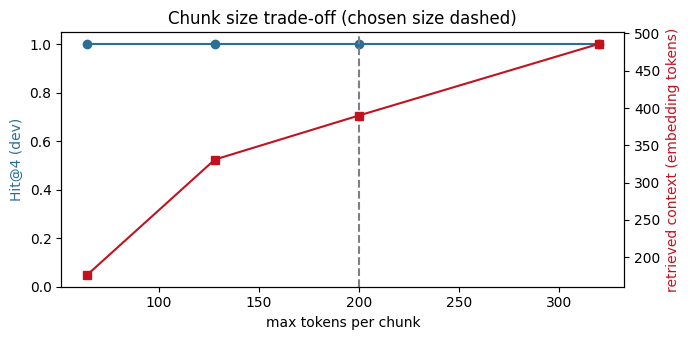

In [ ]:
def dense_eval(chunk_list, questions, k=FINAL_K):
    """Dense-only Hit@k for a candidate chunking (in-memory cosine search, no Qdrant needed)."""
    assert all(len(embed_tokenizer(c["embed_text"])["input_ids"]) <= 512 for c in chunk_list)
    vecs = embed_passages([c["embed_text"] for c in chunk_list])
    hits, ctx = [], []
    for q in questions:
        top = np.argsort(-(vecs @ embed_query(q["question"])))[:k]
        pages = {lbl for i in top for lbl in chunk_list[i]["page_labels"]}
        hits.append(bool(pages & set(q["expected_pages"])))
        ctx.append(sum(chunk_list[i]["n_tokens"] for i in top))
    return np.mean(hits), np.mean(ctx)

in_scope_dev = [q for q in DEV_SET if q["in_scope"]]
rows = []
for size in [64, 128, 200, 320]:
    ch, _ = build_chunks(units, max_tokens=size)
    hit, ctx = dense_eval(ch, in_scope_dev)
    rows.append({"max_tokens": size, "chunks": len(ch),
                 "mean_tokens": round(np.mean([c["n_tokens"] for c in ch])),
                 "pages_per_chunk": round(np.mean([len(c["pdf_pages"]) for c in ch]), 2),
                 "Hit@4 (dev)": round(hit, 2), "context_tokens@4": round(ctx)})
tradeoff = pd.DataFrame(rows)
display(tradeoff)

import matplotlib.pyplot as plt
fig, ax1 = plt.subplots(figsize=(7, 3.5))
ax1.plot(tradeoff.max_tokens, tradeoff["Hit@4 (dev)"], marker="o", color="#2a6f97", label="Hit@4")
ax1.set_xlabel("max tokens per chunk"); ax1.set_ylabel("Hit@4 (dev)", color="#2a6f97"); ax1.set_ylim(0, 1.05)
ax2 = ax1.twinx()
ax2.plot(tradeoff.max_tokens, tradeoff["context_tokens@4"], marker="s", color="#c1121f", label="context tokens")
ax2.set_ylabel("retrieved context (embedding tokens)", color="#c1121f")
ax1.axvline(CHUNK_MAX_TOKENS, ls="--", color="grey"); ax1.set_title("Chunk size trade-off (chosen size dashed)")
fig.tight_layout(); plt.show()

## 4. Qdrant vector database

* **Qdrant Local** (`QdrantClient(path=...)`) stores the collection in a folder on Google Drive — no server needed, and it persists.
* Each point = **384-d vector + payload** (`chunk_id`, `text`, `embed_text`, `section`, `subsection`, `pdf_pages`, `page_labels`, …).
* **Rerun-safe:** point IDs are deterministic (`uuid5(chunk_id)`), so upserting twice overwrites instead of duplicating. A fingerprint
  (hash of the chunk texts + embedding model + PDF hash) detects when the guide or chunking changed; only then is the collection rebuilt.

In [ ]:
from qdrant_client import QdrantClient, models

# Qdrant Local locks its folder: close a client left over from a previous run of this cell.
if "qdrant" in globals():
    try: qdrant.close()
    except Exception: pass

try:
    qdrant = QdrantClient(path=QDRANT_PATH)
except Exception as e:
    print(f"Stale local database found or validation failed: {e}")
    print("Resetting the local database directory to rebuild cleanly...")
    if os.path.exists(QDRANT_PATH):
        shutil.rmtree(QDRANT_PATH)
    if os.path.exists(INDEX_META_PATH):
        os.remove(INDEX_META_PATH)
    qdrant = QdrantClient(path=QDRANT_PATH)

def point_id(chunk_id):
    """Deterministic UUID per chunk -> re-indexing overwrites the same point instead of duplicating it."""
    return str(uuid.uuid5(uuid.NAMESPACE_URL, chunk_id))

# Fingerprint of everything that determines the index contents
FINGERPRINT = hashlib.sha256(json.dumps({
    "pdf": PDF_SHA, "model": EMBED_MODEL_NAME, "dim": EMBED_DIM, "max_tokens": CHUNK_MAX_TOKENS,
    "chunks": chunks,
}).encode()).hexdigest()[:16]

def build_or_reuse_collection(force_rebuild=False):
    """Reuse the stored collection if it matches the current chunks exactly; otherwise rebuild it cleanly."""
    saved = json.load(open(INDEX_META_PATH)) if os.path.exists(INDEX_META_PATH) else {}
    exists = qdrant.collection_exists(COLLECTION)
    if (exists and not force_rebuild and saved.get("fingerprint") == FINGERPRINT
            and qdrant.count(COLLECTION, exact=True).count == len(chunks)):
        print(f"Reusing existing collection '{COLLECTION}' (fingerprint {FINGERPRINT})")
        return
    if exists:
        print("Index is stale or forced -> deleting old collection")
        qdrant.delete_collection(COLLECTION)
    qdrant.create_collection(
        collection_name=COLLECTION,
        vectors_config=models.VectorParams(size=EMBED_DIM, distance=models.Distance.COSINE),
    )
    qdrant.upsert(
        collection_name=COLLECTION,
        points=[models.PointStruct(id=point_id(c["chunk_id"]), vector=v.tolist(), payload=c)
                for c, v in zip(chunks, chunk_vectors)],
        wait=True,
    )
    json.dump({"fingerprint": FINGERPRINT, "chunks": len(chunks), "built": time.ctime()},
              open(INDEX_META_PATH, "w"))
    print(f"Built collection '{COLLECTION}' with {len(chunks)} points (fingerprint {FINGERPRINT})")

build_or_reuse_collection()

# ---- Verification ------------------------------------------------------------
n_points = qdrant.count(COLLECTION, exact=True).count
print(f"Vectors in Qdrant: {n_points} | chunks indexed: {len(chunks)} | match: {n_points == len(chunks)}")
assert n_points == len(chunks)

stored, _ = qdrant.scroll(COLLECTION, limit=10_000, with_payload=True, with_vectors=False)
stored_ids = [p.payload["chunk_id"] for p in stored]
assert set(stored_ids) == set(chunk_by_id)
assert all(p.payload == chunk_by_id[p.payload["chunk_id"]] for p in stored)
assert len(stored_ids) == len(set(stored_ids)), "duplicate chunks in Qdrant!"
print("No duplicate chunk IDs in the collection.")

# Idempotency demo: upserting the same chunks again does NOT add points
qdrant.upsert(COLLECTION, points=[models.PointStruct(id=point_id(c["chunk_id"]), vector=v.tolist(), payload=c)
                                  for c, v in zip(chunks[:5], chunk_vectors[:5])], wait=True)
print(f"After re-upserting 5 chunks the count is still {qdrant.count(COLLECTION, exact=True).count}")
print("Example payload:", {k: stored[0].payload[k] for k in ["chunk_id", "page_display", "section", "subsection"]})

Reusing existing collection 'edab6808_learner_guide' (fingerprint 726317e9bbd6cf02)
Vectors in Qdrant: 58 | chunks indexed: 58 | match: True
No duplicate chunk IDs in the collection.
After re-upserting 5 chunks the count is still 58
Example payload: {'chunk_id': 'edab6808-p12-01', 'page_display': '11', 'section': '4. How Learning Will Take Place', 'subsection': 'Additional Module Features'}


## 5. Retrieval and relevance improvement

**Hybrid retrieval with reranking**

| Stage | What it does | Why |
|---|---|---|
| Dense (Qdrant, top 20) | cosine similarity of BGE vectors | finds paraphrases (“how much is Assignment 5 worth” ↔ “contribution to module mark”) |
| BM25 (top 20) | keyword scoring | exact tokens dense models miss: *FGG 352*, *DIRAP*, *ARIMA*, *Assignment 5* |
| Reciprocal Rank Fusion | `score = Σ 1/(60 + rank)` | merges both lists without having to calibrate their very different score scales |
| Cross-encoder rerank (top 15 → 4) | reads question and chunk *together* | far more accurate than comparing two independent vectors |

**Why k = 4.** Most questions are answered by one chunk; multi-part questions need 2–3 chunks from different places. Four chunks (at most ~800
tokens) cover that with one spare slot, while more chunks mostly add near-duplicates that distract a 3B model and slow generation.
The ablation in §8 shows each stage's contribution.

**Only the strongest evidence reaches the model.** Two rules are applied to the reranked list:
1. *Relevance gate* – if even the best chunk scores below `RETRIEVAL_GATE`, the system abstains without calling the LLM.
   The reranker output is a sigmoid relevance score, not a probability of correctness. The gate is calibrated on the development questions below, which include
   near-miss unsupported questions (deadline, fee, room) as well as unrelated ones.
2. *Strongest-passage filter* – a retrieved chunk is passed to Qwen only if its score is at least `EVIDENCE_MIN_RATIO` (10%) of the best chunk's score,
   so weakly related chunks do not dilute the evidence.

In [ ]:
from rank_bm25 import BM25Okapi
from transformers import AutoModelForSequenceClassification

# ---- BM25 keyword index --------------------------------------------------------
STOPWORDS = set("""a an the and or of to in on for is are was were be been by with as at from that this it its
what which who whom how when where why do does did can could should would will i you your we our they their there
here about into than then so if me my""".split())

def bm25_tokenize(text):
    """Lower-case word tokens (keeps '20%'), no stop words, naive plural stripping."""
    toks = re.findall(r"[a-z0-9]+%?", text.lower())
    toks = [t for t in toks if t not in STOPWORDS]
    return [t[:-1] if len(t) > 4 and t.endswith("s") and not t.endswith("ss") else t for t in toks]

bm25 = BM25Okapi([bm25_tokenize(c["embed_text"]) for c in chunks])

# ---- Cross-encoder reranker ----------------------------------------------------
# Loaded with plain transformers so we control the output: a logit, mapped to a bounded relevance score with a sigmoid.
rr_tokenizer = AutoTokenizer.from_pretrained(RERANK_MODEL_NAME)
rr_model = AutoModelForSequenceClassification.from_pretrained(RERANK_MODEL_NAME).to(RETRIEVAL_DEVICE).eval()

@torch.no_grad()
def rerank_scores(question, passages, batch_size=16):
    """Sigmoid relevance score; not a calibrated probability of correctness."""
    probs = []
    for i in range(0, len(passages), batch_size):
        batch = passages[i:i + batch_size]
        enc = rr_tokenizer([question] * len(batch), batch, padding=True, truncation=True,
                           max_length=512, return_tensors="pt").to(RETRIEVAL_DEVICE)
        probs += torch.sigmoid(rr_model(**enc).logits.view(-1)).float().cpu().tolist()
    return probs

# ---- Individual retrievers -----------------------------------------------------------
def dense_search(question, limit=DENSE_CANDIDATES):
    """Top chunks from Qdrant by cosine similarity -> [(chunk_id, score), ...]."""
    res = qdrant.query_points(COLLECTION, query=embed_query(question).tolist(),
                              limit=limit, with_payload=["chunk_id"]).points
    return [(p.payload["chunk_id"], float(p.score)) for p in res]

def bm25_search(question, limit=BM25_CANDIDATES):
    """Top chunks by BM25 -> [(chunk_id, score), ...] (chunks with zero keyword overlap are dropped)."""
    scores = bm25.get_scores(bm25_tokenize(question))
    order = np.argsort(-scores)[:limit]
    return [(chunks[i]["chunk_id"], float(scores[i])) for i in order if scores[i] > 0]

# ---- Full pipeline ------------------------------------------------------------------
def retrieve(question, k=FINAL_K, use_bm25=True, use_rerank=True):
    """Dense + BM25 -> RRF -> cross-encoder -> top-k.

    Returns a list of hit dicts holding the chunk and every intermediate score,
    so we can inspect / explain the evidence before it reaches the LLM.
    """
    info = defaultdict(lambda: {"dense_rank": None, "dense_score": None,
                                "bm25_rank": None, "bm25_score": None, "rrf": 0.0})
    for rank, (cid, s) in enumerate(dense_search(question), 1):
        info[cid].update(dense_rank=rank, dense_score=round(s, 3))
        info[cid]["rrf"] += 1 / (RRF_K + rank)
    if use_bm25:
        for rank, (cid, s) in enumerate(bm25_search(question), 1):
            info[cid].update(bm25_rank=rank, bm25_score=round(s, 2))
            info[cid]["rrf"] += 1 / (RRF_K + rank)

    pool = sorted(info, key=lambda cid: info[cid]["rrf"], reverse=True)[:RERANK_POOL]
    probs = (rerank_scores(question, [chunk_by_id[c]["embed_text"] for c in pool])
             if use_rerank else [None] * len(pool))
    if use_rerank:
        pool, probs = zip(*sorted(zip(pool, probs), key=lambda t: t[1], reverse=True)) if pool else ([], [])

    q_terms = set(bm25_tokenize(question))
    hits = []
    for rank, (cid, p) in enumerate(zip(pool, probs), 1):
        c = chunk_by_id[cid]
        hits.append({"rank": rank, "chunk": c, **info[cid],
                     "rrf": round(info[cid]["rrf"], 4),
                     "rerank_prob": None if p is None else float(p),
                     "matched_terms": sorted(q_terms & set(bm25_tokenize(c["embed_text"])))})
    return hits[:k]

def select_evidence(hits, gate=None, min_ratio=EVIDENCE_MIN_RATIO):
    """Only the strongest evidence reaches the LLM.

    Returns [] when even the best chunk is below the relevance gate; otherwise keeps the chunks whose
    reranker score is at least `min_ratio` of the best chunk's score (hits are already sorted best-first).
    """
    gate = RETRIEVAL_GATE if gate is None else gate
    if not hits or hits[0]["rerank_prob"] < gate:
        return []
    top = hits[0]["rerank_prob"]
    return [h for h in hits if h["rerank_prob"] >= min_ratio * top]

def retrieval_table(question, k=FINAL_K, **kw):
    """Evidence inspection table: shows WHY each chunk was retrieved."""
    return pd.DataFrame([{
        "rank": h["rank"], "chunk_id": h["chunk"]["chunk_id"], "page": h["chunk"]["page_display"],
        "section": h["chunk"]["section"], "dense_rank": h["dense_rank"], "bm25_rank": h["bm25_rank"],
        "rrf": h["rrf"], "rerank_prob": h["rerank_prob"], "matched_terms": ", ".join(h["matched_terms"]),
        "preview": h["chunk"]["text"][:140].replace("\n", " ") + "…",
    } for h in retrieve(question, k, **kw)])

def explain_hit(question, hit):
    """Human-readable justification of why a chunk is relevant (used in the presentation)."""
    text = hit["chunk"]["text"]
    for term in sorted(hit["matched_terms"], key=len, reverse=True):     # bold the shared keywords
        text = re.sub(rf"\b({re.escape(term)}\w*)", r"**\1**", text, flags=re.I)
    return (f"**{hit['chunk']['chunk_id']}** · {page_ref(hit['chunk'])} · {hit['chunk']['section']}\n\n"
            f"* cross-encoder relevance: **{hit['rerank_prob']}**\n"
            f"* dense rank: {hit['dense_rank']} (cosine {hit['dense_score']}) · BM25 rank: {hit['bm25_rank']}\n"
            f"* shared keywords: {', '.join(hit['matched_terms']) or '—'}\n\n> " + text.replace("\n", "\n> "))

demo_q = "How much does Assignment 5 contribute to the module mark?"
print(demo_q); display(retrieval_table(demo_q))
display(Markdown(explain_hit(demo_q, retrieve(demo_q)[0])))

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

How much does Assignment 5 contribute to the module mark?


,rank,chunk_id,page,section,dense_rank,bm25_rank,rrf,rerank_prob,matched_terms,preview
0,1,edab6808-p15-07,14,7. Assessment of Learning,2,1,0.0325,0.997009,"5, assignment, mark, module",ASSESSMENT: Assignment 5 | TYPE (E.G. WRITTEN/ORAL/PRACTICAL): Notebook + PowerPoint presentation 30 minutes per gro...
1,2,edab6808-p15-08,14,7. Assessment of Learning,3,2,0.0320,0.980824,"assignment, mark, module","ASSESSMENT: Assignment 6 | TYPE (E.G. WRITTEN/ORAL/PRACTICAL): ePortfolio group (20 minutes presentation, 10 minutes..."
2,3,edab6808-p15-06,14,7. Assessment of Learning,4,5,0.0310,0.966877,"assignment, mark, module",ASSESSMENT: Assignment 4 | TYPE (E.G. WRITTEN/ORAL/PRACTICAL): Notebook + PowerPoint presentation 30 minutes per gro...
3,4,edab6808-p15-03,14,7. Assessment of Learning,7,7,0.0299,0.949365,"assignment, mark, module",ASSESSMENT: Assignment 1 | TYPE (E.G. WRITTEN/ORAL/PRACTICAL): LookerStudio + Notebook + PowerPoint presentation 30 ...


**edab6808-p15-07** · p. 14 · 7. Assessment of Learning

* cross-encoder relevance: **0.9970093369483948**
* dense rank: 2 (cosine 0.723) · BM25 rank: 1
* shared keywords: 5, assignment, mark, module

> ASSESSMENT: **Assignment** **5** | TYPE (E.G. WRITTEN/ORAL/PRACTICAL): Notebook + PowerPoint presentation 30 minutes per group (20 minutes presentation, 10 minutes Q&A). | CONTRIBUTION TO **MODULE** **MARK** (weight): 20%

In [ ]:
# ---------------------------------------------------------------------------
# Calibrate the relevance gate on the DEVELOPMENT set (not on the evaluation questions)
# ---------------------------------------------------------------------------
calib = []
for q in DEV_SET:
    hits = retrieve(q["question"])
    calib.append({"question": q["question"], "in_scope": q["in_scope"],
                  "top_rerank_prob": hits[0]["rerank_prob"] if hits else 0.0,
                  "top_page": hits[0]["chunk"]["page_display"] if hits else None})
calib_df = pd.DataFrame(calib); display(calib_df)

ins  = calib_df[calib_df.in_scope].top_rerank_prob
outs = calib_df[~calib_df.in_scope].top_rerank_prob

if ins.min() > outs.max():
    # The two groups are separable: put the gate in the middle of the gap (geometric mean on the probability scale).
    RETRIEVAL_GATE = float(max(np.sqrt(max(outs.max(), 1e-6) * ins.min()), 0.05))
    print(f"Lowest in-scope score {ins.min():.3f} > highest out-of-scope score {outs.max():.3f}")
else:
    # Overlap: choose the threshold with the best balanced accuracy.
    values = sorted(set(calib_df.top_rerank_prob))
    cands = [0.0] + [(a + b) / 2 for a, b in zip(values, values[1:])] + [1.000001]
    RETRIEVAL_GATE = float(max(cands, key=lambda t: (((ins >= t).mean() + (outs < t).mean()) / 2, (outs < t).mean(), t)))
    print("In-scope and out-of-scope scores overlap; using the best balanced-accuracy threshold")
print(f"Relevance gate (RETRIEVAL_GATE) = {RETRIEVAL_GATE:.3f}")

,question,in_scope,top_rerank_prob,top_page
0,What is the phone number for the lecturers?,True,0.950894,2
1,Which techniques are covered in the synthetic data generation unit?,True,0.997498,8
2,Which Python libraries will students use in the practical sessions?,True,0.997940,10
3,What does Assignment 1 consist of?,True,0.739393,14
4,Which values are students expected to carry themselves with?,True,0.971952,14–15
5,What is continuous assessment according to rule 1.5?,True,0.999520,13–14
6,What is the parking policy on the Bloemfontein campus?,False,0.000015,12
7,How do I bake sourdough bread?,False,0.000016,3–4
8,What is the deadline for submitting Assignment 3?,False,0.158014,14
9,What is the tuition fee for this module?,False,0.004239,5


Lowest in-scope score 0.739 > highest out-of-scope score 0.158
Relevance gate (RETRIEVAL_GATE) = 0.342


## 6. Grounded generation with Qwen

* **Model:** `Qwen/Qwen2.5-3B-Instruct`, Qwen's instruction-tuned (post-trained) chat model, loaded locally with  Transformers in fp16 (about 6 GB on a T4).
  local instruction-tuned Qwen; this is that model. No extra fine-tuning is performed.
* **Only the strongest evidence** (reranked chunks that passed the gate and the strongest-passage filter, at most 4) is placed in the prompt, labelled `[E1]…[E4]`.
  The labels carry no page numbers, so the model *cannot* invent them; citations are attached afterwards from the stored Qdrant metadata.
* The system prompt tells the model to use **only** the supplied passages, to copy names and numbers exactly, and to reply `INSUFFICIENT_EVIDENCE` when the passages do not state the answer.
* **Greedy decoding** (`do_sample=False`) makes answers deterministic and reproducible for the evaluation. No repetition penalty is used, because it would discourage the model from copying names and numbers out of the evidence.

In [ ]:
from transformers import AutoModelForCausalLM

llm_tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
try:   # newer transformers name the argument `dtype`, older ones `torch_dtype`
    llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, dtype=DTYPE, device_map={"": DEVICE})
except TypeError:
    llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, torch_dtype=DTYPE, device_map={"": DEVICE})
llm.eval()
print(f"Loaded {LLM_NAME} ({sum(p.numel() for p in llm.parameters()) / 1e9:.2f}B parameters) on {llm.device}")

@torch.no_grad()
def generate(messages, max_new_tokens=MAX_NEW_TOKENS):
    """Run the chat model greedily and return only the newly generated text."""
    prompt = llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    enc = llm_tokenizer(prompt, return_tensors="pt").to(llm.device)
    if enc["input_ids"].shape[1] + max_new_tokens > min(8192, llm.config.max_position_embeddings):
        raise ValueError("Question and evidence exceed the context budget; shorten the question.")
    out = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                       temperature=None, top_p=None, top_k=None,         # silence sampling warnings
                       repetition_penalty=1.0, pad_token_id=llm_tokenizer.eos_token_id)   # no penalty: the answer must copy terms from the evidence
    return llm_tokenizer.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

print(generate([{"role": "user", "content": "Reply with the single word: ready"}], max_new_tokens=5))

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.97G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-3B-Instruct (3.09B parameters) on cuda:0
ready


In [ ]:
ABSTAIN_TOKEN = "INSUFFICIENT_EVIDENCE"

SYSTEM_PROMPT = f"""You answer questions about the EDAB 6808 Learner Guide using only the numbered passages supplied with each question.

How to answer:
- Read the passages and answer from them. Copy names, numbers and terms exactly as written.
- Do not use outside knowledge.
- After each statement, add the label of the passage it came from, for example [E1] or [E2].
- Be brief: one to four sentences, or a short list.
- Only if none of the passages states the answer, reply with exactly {ABSTAIN_TOKEN} and nothing else.
- If the passages answer only part of the question, answer that part and say which part the guide does not state.

Example (a different, made-up document):
Passages: [E1] The library opens at 08:00 and closes at 20:00 on weekdays.
Question: When does the library close on weekdays?
Answer: The library closes at 20:00 on weekdays [E1].
Question: Who is the head librarian?
Answer: {ABSTAIN_TOKEN}"""

def build_messages(question, hits):
    """Chat messages: system rules + labelled evidence + the question. No page numbers are given to the model."""
    evidence = "\n\n".join(
        f"[E{i}] (Section: {h['chunk']['section']}"
        + (f" › {h['chunk']['subsection']}" if h["chunk"]["subsection"] else "") + ")\n"
        + h["chunk"]["text"]
        for i, h in enumerate(hits, 1))
    user = f"Passages from the EDAB 6808 Learner Guide:\n\n{evidence}\n\nQuestion: {question}\nAnswer:"
    return [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]

demo_hits = select_evidence(retrieve(demo_q))
print(f"{len(demo_hits)} passage(s) passed to the model for: {demo_q}\n")
print(build_messages(demo_q, demo_hits)[1]["content"][:900], "…")

4 passage(s) passed to the model for: How much does Assignment 5 contribute to the module mark?

Passages from the EDAB 6808 Learner Guide:

[E1] (Section: 7. Assessment of Learning)
ASSESSMENT: Assignment 5 | TYPE (E.G. WRITTEN/ORAL/PRACTICAL): Notebook + PowerPoint presentation 30 minutes per group (20 minutes presentation, 10 minutes Q&A). | CONTRIBUTION TO MODULE MARK (weight): 20%

[E2] (Section: 7. Assessment of Learning)
ASSESSMENT: Assignment 6 | TYPE (E.G. WRITTEN/ORAL/PRACTICAL): ePortfolio group (20 minutes presentation, 10 minutes Q&A). | CONTRIBUTION TO MODULE MARK (weight): 10%

[E3] (Section: 7. Assessment of Learning)
ASSESSMENT: Assignment 4 | TYPE (E.G. WRITTEN/ORAL/PRACTICAL): Notebook + PowerPoint presentation 30 minutes per group (20 minutes presentation, 10 minutes Q&A). | CONTRIBUTION TO MODULE MARK (weight): 15%

[E4] (Section: 7. Assessment of Learning)
ASSESSMENT: Assignment 1 | TYPE (E.G. WRITTEN/ORAL/PRACTICAL): LookerStudio + Notebook + PowerPoint presen …


## 7. Citations and abstention

* **Citations come from stored metadata.** The application attaches the page, section and chunk ID saved in Qdrant; the model never writes them.
  Each citation gives the printed guide page (the "N | Page" footer) and the PDF page number.
* **Citations are verified (§7a).** The model's `[E#]` labels are not trusted blindly: every statement of the answer is linked to the passage(s) that actually contain its numbers and key terms.
* **A faithfulness check (§7a)** reports how many statements are supported by the evidence.
* **Abstention.** The assistant refuses when (a) the best retrieved chunk is below the relevance gate, (b) the model replies `INSUFFICIENT_EVIDENCE`,
  or (c) the answer still fails validation after one repair attempt. Validation rejects empty answers and numbers that appear neither in the evidence nor in the question.
* Abstaining means the pipeline could not support an answer from the retrieved evidence.

### 7a. Citation verification and faithfulness check

Two deterministic checks run after Qwen has answered. Neither uses an LLM.

**Citation verification.** Qwen writes passage labels such as `[E1]`, but a 3B model sometimes attaches the wrong label, especially when one answer combines facts from two places in the guide.
The application therefore checks every statement itself:
1. The answer is split into statements (one per sentence or bullet).
2. For each statement, the key terms and numbers are weighted by BM25 inverse document frequency (numbers count double, because a wrong number is the most damaging error).
3. The passages that were given to Qwen are scored by how much of that weight they contain. A passage is cited if it covers at least `CITE_MIN_FIRST` (30%) of the statement; a second passage is added only if it covers at least `CITE_MIN_GAIN` (12%) *more*.
4. The model's own label only breaks ties (`CITE_LABEL_BONUS`). If no passage covers the statement well enough, the model's label is kept and the statement is marked *unverified*.

The citations shown to the user (page, section, chunk ID) are then built from the **verified** labels and the stored Qdrant metadata.

**Faithfulness check.** For every statement in the answer the application measures
* *semantic support*: the cosine similarity between the statement and its closest sentence in the evidence (BGE embeddings), and
* *lexical support*: the share of the statement's weighted key terms that appear in the evidence.

A statement is *supported* only if both pass. The similarity threshold is not guessed: it is calibrated below from **negative controls built from the guide itself**
(guide sentences compared with sentences from unrelated sections), so that unrelated text is rejected 95% of the time.
Faithfulness = share of statements supported. It is a proxy: it detects statements that are not grounded in the evidence, but it cannot prove that a statement means the same as its source.

In [ ]:
import random

# The labels the model writes, and list markers at the start of a line
CITE_RE        = re.compile(r"\[E(\d+)\]")
LIST_MARKER_RE = re.compile(r"^\s*(?:[-*•]|\d+[.)])\s+")

# ---------------------------------------------------------------------------
# Statements: the units that carry one citation each
# ---------------------------------------------------------------------------
def split_answer(text):
    """Split an answer into lines, and each line into sentences (citation labels are kept).

    Returns [(list_marker_prefix, [sentence, ...]), ...]
    """
    out = []
    for line in text.splitlines():
        line = line.strip()
        if not line:
            continue
        line = re.sub(r"([.!?])\s+(\[E\d+\])", r" \2\1", line)      # 'hours. [E1]' -> 'hours [E1].'
        m = LIST_MARKER_RE.match(line)
        prefix, body = (line[:m.end()], line[m.end():]) if m else ("", line)
        out.append((prefix, split_sentences(body)))
    return out

def _tok_weights(tokens):
    """BM25 idf weight per key term; numbers count double (a wrong number is the most damaging error)."""
    return {t: max(bm25.idf.get(t, 1.0), 0.3) * (2.0 if t[0].isdigit() else 1.0) for t in tokens}

# ---------------------------------------------------------------------------
# Citation verification
# ---------------------------------------------------------------------------
def pick_passages(statement, ev_tokens, model_labels):
    """Greedy cover: which evidence passages contain the statement's key terms and numbers?

    Returns (list of evidence indices, share of the statement's weighted terms covered).
    """
    toks = set(bm25_tokenize(statement))
    if len(toks) < 2:
        return [], 0.0
    w = _tok_weights(toks)
    total = sum(w.values())
    covered, picked, remaining = set(), [], set(range(len(ev_tokens)))
    while remaining:
        best, best_gain, best_score = None, 0.0, 0.0
        for j in remaining:
            gain = sum(w[t] for t in (toks & ev_tokens[j]) - covered) / total
            score = gain + (CITE_LABEL_BONUS if (j + 1) in model_labels and gain > 0 else 0.0)
            if score > best_score:
                best, best_gain, best_score = j, gain, score
        need = CITE_MIN_FIRST if not picked else CITE_MIN_GAIN
        if best is None or best_gain < need:
            break
        picked.append(best)
        covered |= toks & ev_tokens[best]
        remaining.discard(best)
        if sum(w[t] for t in covered) / total >= 0.90:
            break
    return picked, sum(w[t] for t in covered) / total

def verify_citations(answer_text, evidence):
    """Re-attach citation labels to each statement using the evidence text, not the model's choice.

    Returns (answer text with verified labels, log with one entry per statement).
    """
    ev_tokens = [set(bm25_tokenize(h["chunk"]["text"])) for h in evidence]
    lines, log = [], []
    for prefix, sentences in split_answer(answer_text):
        line_labels = [int(n) for s in sentences for n in CITE_RE.findall(s)]
        parts = []
        for s in sentences:
            core = CITE_RE.sub("", s).strip()
            punct = re.search(r"[.!?:]+$", core)
            punct = punct.group(0) if punct else ""
            core = core[:len(core) - len(punct)].rstrip()
            if not core:
                continue
            model = [int(n) for n in CITE_RE.findall(s)] or line_labels
            model = [n for n in dict.fromkeys(model) if 1 <= n <= len(evidence)]
            picked, cov = pick_passages(core, ev_tokens, model)
            if picked:
                labels = [j + 1 for j in picked]
                status = "confirmed" if set(labels) == set(model) else "corrected"
            else:
                labels = model
                status = "unverified (model label kept)" if model else "no label"
            tag = "".join(f"[E{n}]" for n in labels)
            parts.append(f"{core} {tag}{punct}".strip() if tag else f"{core}{punct}")
            log.append({"statement": core, "model_labels": model, "verified_labels": labels,
                        "coverage": round(cov, 2), "status": status})
        if parts:
            lines.append(prefix + " ".join(parts))
    return "\n".join(lines), log

# ---------------------------------------------------------------------------
# Faithfulness check
# ---------------------------------------------------------------------------
def calibrate_faith_threshold(n_neg_chunks=4, quantile=0.95, seed=42):
    """Similarity threshold from negative controls built from the guide itself.

    Each guide sentence is compared with the sentences and whole passages of a few chunks from OTHER sections; the
    threshold is the 95th percentile of those best-match similarities, so unrelated text is rejected 95% of the time.
    """
    rng = random.Random(seed)
    flat = [(c["chunk_id"], s) for c in chunks for s in split_sentences(c["text"])]
    n_sent = len(flat)
    flat += [(c["chunk_id"], c["text"]) for c in chunks]                 # whole passages are evidence units too
    vecs = embed_passages([s for _, s in flat])
    index = defaultdict(list)
    for i, (cid, _) in enumerate(flat):
        index[cid].append(i)
    neg_best = []
    for i, (cid, s) in enumerate(flat[:n_sent]):                         # probes: guide sentences
        if len(s.split()) < 6 or chunk_by_id[cid]["kind"] != "prose":
            continue
        others = [c for c in chunk_by_id if chunk_by_id[c]["section"] != chunk_by_id[cid]["section"]]
        pick = rng.sample(others, min(n_neg_chunks, len(others)))
        idx = [j for c in pick for j in index[c]]
        neg_best.append(float((vecs[idx] @ vecs[i]).max()))
    return float(np.quantile(neg_best, quantile)), np.array(neg_best)

_thr, _neg = calibrate_faith_threshold()
FAITH_SIM_THR = float(np.clip(_thr, 0.55, 0.90))    # safety bounds around the calibrated value
print(f"Negative controls: {len(_neg)} guide sentences vs. chunks from other sections -> "
      f"median best-match similarity {np.median(_neg):.3f}, 95th percentile {_thr:.3f}")
print(f"Semantic-support threshold FAITH_SIM_THR = {FAITH_SIM_THR:.3f}; lexical-support threshold FAITH_LEX_THR = {FAITH_LEX_THR}")

def faithfulness_check(answer_text, evidence):
    """Is each statement of the answer supported by the evidence that was passed to the model?

    The statement is compared with every evidence sentence, every whole evidence passage and, when the statement
    cites two or more passages, with those passages joined together (a statement may combine facts from two places).
    """
    items = []
    for _, sents in split_answer(answer_text):
        for s in sents:
            core = CITE_RE.sub("", s).strip()
            if len(core.split()) >= 3:
                labels = [int(n) for n in dict.fromkeys(CITE_RE.findall(s)) if 1 <= int(n) <= len(evidence)]
                items.append((core, labels))
    if not items or not evidence:
        return {"score": np.nan, "n": 0, "supported": 0, "all_supported": None, "details": []}
    units = [(f"E{j + 1}", u) for j, h in enumerate(evidence) for u in split_sentences(h["chunk"]["text"])]
    units += [(f"E{j + 1}", h["chunk"]["text"]) for j, h in enumerate(evidence)]
    S = embed_passages([c for c, _ in items])
    sims = S @ embed_passages([u for _, u in units]).T
    ev_all = set().union(*[set(bm25_tokenize(h["chunk"]["text"])) for h in evidence])
    details = []
    for i, (core, labels) in enumerate(items):
        k = int(np.argmax(sims[i]))
        sim, where, closest = float(sims[i, k]), units[k][0], units[k][1]
        if len(labels) >= 2:
            joined = "\n".join(evidence[n - 1]["chunk"]["text"] for n in labels)
            sj = float(S[i] @ embed_passages([joined])[0])
            if sj > sim:
                sim, where, closest = sj, "+".join(f"E{n}" for n in labels), "(cited passages joined)"
        toks = set(bm25_tokenize(core))
        w = _tok_weights(toks)
        lex = sum(w[t] for t in toks & ev_all) / (sum(w.values()) or 1.0)
        details.append({"statement": core, "similarity": round(sim, 3), "lexical": round(lex, 3),
                        "supported": bool(sim >= FAITH_SIM_THR and lex >= FAITH_LEX_THR),
                        "closest_passage": where, "closest_text": closest})
    n_ok = sum(d["supported"] for d in details)
    return {"score": n_ok / len(details), "n": len(details), "supported": n_ok,
            "all_supported": n_ok == len(details), "details": details}

# ---- Demonstration: a deliberately wrong label is corrected from the evidence ----
demo_q2 = "How many hours of class are there per week, and what types of contact sessions are held each week?"
demo_ev = select_evidence(retrieve(demo_q2))
demo_answer = "There are 4-6 hours of class per week [E1].\nThe contact sessions are one theory class and one practical class [E1]."
fixed, demo_log = verify_citations(demo_answer, demo_ev)
print(f"\nEvidence passages: " + " | ".join(f"E{i} = {page_ref(h['chunk'])}" for i, h in enumerate(demo_ev, 1)))
print("Model labelled both statements [E1]. After verification:\n" + fixed + "\n")
display(pd.DataFrame(demo_log))
display(pd.DataFrame(faithfulness_check(fixed, demo_ev)["details"])[["statement", "similarity", "lexical", "supported", "closest_passage"]])

Negative controls: 162 guide sentences vs. chunks from other sections -> median best-match similarity 0.651, 95th percentile 0.764
Semantic-support threshold FAITH_SIM_THR = 0.764; lexical-support threshold FAITH_LEX_THR = 0.6

Evidence passages: E1 = p. 11 | E2 = p. 5
Model labelled both statements [E1]. After verification:
There are 4-6 hours of class per week [E2].
The contact sessions are one theory class and one practical class [E1].



,statement,model_labels,verified_labels,coverage,status
0,There are 4-6 hours of class per week,[1],[2],1.0,corrected
1,The contact sessions are one theory class and one practical class,[1],[1],1.0,confirmed


,statement,similarity,lexical,supported,closest_passage
0,There are 4-6 hours of class per week .,0.844,1.0,True,E2
1,The contact sessions are one theory class and one practical class .,0.871,1.0,True,E1


In [ ]:
NUM_RE = re.compile(r"\d+(?:[.,]\d+)?")

def cite_label(chunk):
    """Citation text built ONLY from stored Qdrant metadata: printed page, PDF page, section, chunk ID."""
    pdf = chunk["pdf_pages"]
    pdf_txt = str(pdf[0]) if len(pdf) == 1 else f"{pdf[0]}–{pdf[-1]}"
    where = chunk["section"] + (f" › {chunk['subsection']}" if chunk["subsection"] else "")
    return f"Learner Guide {page_ref(chunk)} (PDF page {pdf_txt}) · {where} · `{chunk['chunk_id']}`"

def abstain_message(hits, reason):
    closest = "; ".join(f"{page_ref(h['chunk'])} ({h['chunk']['section']})" for h in hits[:3]) or "none"
    return (" **I cannot answer this from the Learner Guide.** "
            "The retrieved passages do not contain enough evidence, so I will not guess.\n\n"
            f"_Reason: {reason}. Closest passages checked: {closest}._")

def is_abstention(raw):
    r = raw.strip()
    return bool(re.match(r"^\W*INSUFFICIENT[_ ]EVIDENCE", r, re.I) or (ABSTAIN_TOKEN in r.upper() and len(r) < 120))

def check_answer(raw, evidence, question):
    """Light structural checks. Returns (ok, reason, cleaned_text)."""
    lines = []
    for line in raw.splitlines():
        line = line.strip()
        if not line:
            continue
        # drop labels that do not exist among the supplied passages
        line = CITE_RE.sub(lambda m: m.group(0) if 1 <= int(m.group(1)) <= len(evidence) else "", line).strip()
        # '[E1] claim ... [E1]' -> 'claim ... [E1]'
        m = re.match(r"^((?:\[E\d+\]\s*)+)(.*)$", line)
        if m and CITE_RE.search(m.group(2)):
            line = m.group(2).strip()
        if line:
            lines.append(line)
    text = "\n".join(lines)
    if not re.search(r"[A-Za-z]{3}|\d", CITE_RE.sub("", text)):
        return False, "the answer is empty", text
    allowed = set(NUM_RE.findall(question)) | set(NUM_RE.findall(" ".join(h["chunk"]["text"] for h in evidence)))
    for line in lines:
        claim = LIST_MARKER_RE.sub("", CITE_RE.sub("", line))
        extra = set(NUM_RE.findall(claim)) - allowed
        if extra:
            return False, f"number(s) {sorted(extra)} do not appear in the evidence", text
    return True, None, text

def ask(question, k=FINAL_K, gate=None):
    """Full RAG pipeline: retrieve -> filter evidence -> generate -> validate -> cite from metadata, or abstain."""
    question = question.strip()
    if not question or len(question) > 2000:
        raise ValueError("Enter a question of 1–2000 characters.")
    t0 = time.perf_counter()
    hits = retrieve(question, k=k)
    evidence = select_evidence(hits, gate)
    res = {"question": question, "hits": hits, "evidence": evidence, "retrieval_s": time.perf_counter() - t0,
           "generation_s": 0.0, "raw_output": "", "cited": [], "warnings": [], "abstained": False,
           "abstain_reason": None, "citation_basis": None,
           "citation_check": [], "cited_model_labels": [], "citations_changed": False, "faithfulness": None}
    reason, answer_text = None, ""
    if not evidence:
        reason = "the retrieved passages did not pass the relevance gate"
    else:
        t1 = time.perf_counter()
        messages = build_messages(question, evidence)
        raw = generate(messages)
        for attempt in range(2):
            if is_abstention(raw):
                reason = "the language model found the evidence insufficient"
                break
            ok, why, answer_text = check_answer(raw, evidence, question)
            if ok:
                reason = None
                break
            reason = f"the answer failed validation ({why})"
            if attempt == 0:     # one bounded repair attempt
                res["warnings"].append(f"First answer rejected: {why}; one repair attempt.")
                raw = generate(messages + [
                    {"role": "assistant", "content": raw},
                    {"role": "user", "content": f"That answer is not acceptable ({why}). Answer again using only the passages, "
                                                f"with a label such as [E1] after each statement. If they do not state the answer, reply {ABSTAIN_TOKEN}."}])
        res["generation_s"] = time.perf_counter() - t1
        res["raw_output"] = raw
    if reason:
        res.update(abstained=True, abstain_reason=reason, answer="", answer_md=abstain_message(hits, reason))
    else:
        # Labels as written by the model (kept only to measure what the verification changes)
        model_order = list(dict.fromkeys(int(n) for n in CITE_RE.findall(answer_text)))
        res["cited_model_labels"] = [evidence[n - 1] for n in (model_order or range(1, len(evidence) + 1))]
        # Re-attach labels from the evidence text, then build the citations from them
        answer_text, res["citation_check"] = verify_citations(answer_text, evidence)
        res["citations_changed"] = any(e["status"] == "corrected" for e in res["citation_check"])
        order = list(dict.fromkeys(int(n) for n in CITE_RE.findall(answer_text)))
        if order:
            res["citation_basis"] = "each statement linked to the passage(s) containing its numbers and key terms"
        else:
            order = list(range(1, len(evidence) + 1))
            res["citation_basis"] = "no passage could be matched to the statements; all passages passed to the model are listed"
        renumber = {n: i for i, n in enumerate(order, 1)}
        answer = CITE_RE.sub(lambda m: f"[{renumber[int(m.group(1))]}]", answer_text)
        res["cited"] = [evidence[n - 1] for n in order]
        res["faithfulness"] = faith = faithfulness_check(answer_text, evidence)
        if faith["n"] and not faith["all_supported"]:
            res["warnings"].append(f"{faith['n'] - faith['supported']} of {faith['n']} statements are not closely matched by the evidence.")
        sources = "\n".join(f"[{i}] {cite_label(h['chunk'])}" for i, h in enumerate(res["cited"], 1))
        note = (f"\n\n<sub>Faithfulness check: {faith['supported']}/{faith['n']} statements supported by the evidence.</sub>"
                if faith["n"] else "")
        res.update(answer=answer, answer_md=answer + "\n\n**Sources**\n" + sources + note)
    res["total_s"] = time.perf_counter() - t0
    return res

# ---- Demonstration: a direct question, a multi-part question and an unrelated question ----
for q in ["How many notional learning hours does this module require?",
          "How many weeks is the NLP unit and which topics does it cover?",
          "Who won the 2023 Rugby World Cup?"]:
    r = ask(q)
    display(Markdown(f"### Q: {q}\n\n{r['answer_md']}\n\n"
                     f"<sub>retrieval {r['retrieval_s']:.2f}s · generation {r['generation_s']:.2f}s · "
                     f"total {r['total_s']:.2f}s</sub>"))

### Q: How many notional learning hours does this module require?

This module requires a minimum of 320 notional learning hours [1].

**Sources**
[1] Learner Guide p. 5 (PDF page 6) · 4. How Learning Will Take Place · `edab6808-p06-01`

<sub>Faithfulness check: 1/1 statements supported by the evidence.</sub>

<sub>retrieval 0.98s · generation 1.22s · total 2.91s</sub>

### Q: How many weeks is the NLP unit and which topics does it cover?

The NLP unit covers 2 weeks [1][2]. It focuses on applying NLP techniques to analyse unstructured social media text, extracting sentiment and topics to inform business strategies [1].

**Sources**
[1] Learner Guide p. 12 (PDF page 13) · 5. Module Schedule · `edab6808-p13-07`
[2] Learner Guide p. 12 (PDF page 13) · 5. Module Schedule · `edab6808-p13-06`

<sub>Faithfulness check: 2/2 statements supported by the evidence.</sub>

<sub>retrieval 1.12s · generation 2.94s · total 5.24s</sub>

### Q: Who won the 2023 Rugby World Cup?

⚠️ **I cannot answer this from the Learner Guide.** The retrieved passages do not contain enough evidence, so I will not guess.

_Reason: the retrieved passages did not pass the relevance gate. Closest passages checked: p. 3–4 (2. Module Description); p. 3–4 (2. Module Description); p. 4–5 (3. Graduate Attributes)._

<sub>retrieval 0.88s · generation 0.00s · total 0.88s</sub>

## 8. Evaluation

The system is evaluated on **20 questions written from the learner guide: 14 direct factual, 3 multi-part (evidence from two places in the guide) and 3 that the guide cannot answer.**
The answerable questions cover 9 sections of the guide (cover page, instructor information, graduate attributes, how learning takes place, module schedule, list of materials,
assessment, policies and evaluation procedures). They are separate from the development questions used to calibrate the relevance gate and the chunk size.

For every question the test records the expected source, whether the correct evidence was retrieved, whether the answer was correct, whether the citation was correct and the response time.

**How each measure is computed**
* *Hit@k*, *MRR*, *context precision* and *context recall* are the retrieval measures of the RAGAS framework, computed against annotated gold chunks .
* *Answer accuracy*: the system did not abstain and the answer contains every key fact listed for the question.
* *Citation accuracy*: the cited chunks include the gold source for every part of the question.
* *Citation accuracy (model labels only)* repeats the same check on the labels exactly as Qwen wrote them, so the effect of citation verification (§7a) is measured, not assumed.
* *Faithfulness (proxy)*: share of answer statements supported by the evidence (semantic similarity above a threshold calibrated on the guide itself, and lexical coverage of the statement's key terms).
* *Abstention success rate*: share of unsupported questions that were refused. *False abstention rate*: share of answerable questions that were refused.
* Any verdict can be overridden after reading the answer (`MANUAL_REVIEW` below); the summary uses the override when one is given.

In [ ]:
# ---------------------------------------------------------------------------
# Evaluation / demonstration set: 20 questions written from the Learner Guide.
#   14 direct factual  |  3 multi-part (evidence from two places)  |  3 not answerable from the guide
# These questions are separate from the development questions used to calibrate the gate (§3, §5).
# answer_patterns: key facts (regex) that must all appear in a correct answer.
# GOLD: the guide passage(s) that answer each question: (printed page(s), [regexes that must all match the chunk]).
#       A multi-part question lists one entry per part; every part has to be retrieved.
# ---------------------------------------------------------------------------
TEST_SET = [
    # ---------------- direct factual (14) ----------------
    dict(id="F01", type="factual", question="What is the lecturers' office number?",
         expected_answer="FGG 352", answer_patterns=[r"FGG\s*352"]),
    dict(id="F02", type="factual", question="How many credits is EDAB6808 and at what NQF level is it offered?",
         expected_answer="32 credits, NQF level 8", answer_patterns=[r"\b32\b", r"\b8\b"]),
    dict(id="F03", type="factual", question="What is the minimum number of notional learning hours needed to pass the module?",
         expected_answer="320 notional learning hours", answer_patterns=[r"\b320\b"]),
    dict(id="F04", type="factual", question="Which forecasting methods are applied in Unit 1?",
         expected_answer="ARIMA, exponential smoothing and advanced decomposition", answer_patterns=[r"ARIMA", r"exponential smoothing"]),
    dict(id="F05", type="factual", question="How many weeks are allocated to Unit 4 in the module schedule?",
         expected_answer="3 weeks", answer_patterns=[r"\b3\b|three"]),
    dict(id="F06", type="factual", question="What percentage of the module mark does Assignment 5 contribute?",
         expected_answer="20%", answer_patterns=[r"20\s*%"]),
    dict(id="F07", type="factual", question="What happens if a student misses an assessment opportunity without a valid reason?",
         expected_answer="The student receives an incomplete for the module", answer_patterns=[r"incomplete"]),
    dict(id="F08", type="factual", question="What percentage of sessions are students expected to attend?",
         expected_answer="100% of the sessions", answer_patterns=[r"100\s*%"]),
    dict(id="F09", type="factual", question="Who might contact students for an independent module assessment?",
         expected_answer="DIRAP", answer_patterns=[r"DIRAP"]),
    dict(id="F10", type="factual", question="Is there a prescribed textbook for this module?",
         expected_answer="No, there is no prescribed textbook", answer_patterns=[r"\bno\b|not"]),
    dict(id="F11", type="factual", question="How does the UFS define digital competency?",
         expected_answer="The ability to engage with, use and create technologies to enable learning and working in a digital society",
         answer_patterns=[r"engage with", r"create"]),
    dict(id="F12", type="factual", question="What should the subject line of an appointment email contain?",
         expected_answer="The student number, plus one word summarising the nature of the email", answer_patterns=[r"student number", r"one|1|word"]),
    dict(id="F13", type="factual", question="Which tool do students use to build dashboards in this module?",
         expected_answer="Looker Studio", answer_patterns=[r"Looker\s*Studio"]),
    dict(id="F14", type="factual", question="Which visual tools does Unit 2 use to analyse data distributions?",
         expected_answer="Histograms, scatter plots and box plots", answer_patterns=[r"histogram", r"scatter", r"box\s*plot"]),
    # ---------------- multi-part: evidence from two places (3) ----------------
    dict(id="M01", type="multi", question="How many weeks does the NLP for social media unit take, and which techniques does it cover?",
         expected_answer="2 weeks (schedule); text preprocessing, sentiment analysis and topic modelling (Unit 6)",
         answer_patterns=[r"\b2\b|two", r"sentiment", r"topic"]),
    dict(id="M02", type="multi", question="How many hours of class are there per week, and what types of contact sessions are held each week?",
         expected_answer="4-6 hours of class per week; one theory class and one practical class",
         answer_patterns=[r"4\s*(?:-|–|to)\s*6", r"theory", r"practical"]),
    dict(id="M03", type="multi", question="What are the components of a Bayesian network covered in Unit 3, and how many class lectures does Unit 3 have?",
         expected_answer="Nodes, edges and conditional probabilities; 3 class lectures",
         answer_patterns=[r"node", r"\b3\b|three"]),
    # ---------------- not answerable from the guide (3) ----------------
    dict(id="O01", type="oos", question="What is the pass mark for the EDAB6808 final exam?",
         expected_answer="Refuse - the guide gives no exam pass mark", answer_patterns=[]),
    dict(id="O02", type="oos", question="What is the penalty for submitting an assignment late?",
         expected_answer="Refuse - the guide states no late-submission penalty", answer_patterns=[]),
    dict(id="O03", type="oos", question="Who won the 2023 Rugby World Cup?",
         expected_answer="Refuse - unrelated to the guide", answer_patterns=[]),
]

GOLD = {
    "F01": [([2],  [r"FGG\s*352"])],
    "F02": [([0],  [r"32\s*Credits", r"NQF\s*level\s*8"])],
    "F03": [([5],  [r"320\s+notional"])],
    "F04": [([6],  [r"ARIMA", r"exponential smoothing"])],
    "F05": [([12], [r"UNIT Number:\s*4\b", r"WEEKS for Unit:\s*3\b"])],
    "F06": [([14], [r"Assignment 5", r"20%"])],
    "F07": [([14], [r"without a valid reason", r"incomplete"])],
    "F08": [([15], [r"100% of the sessions"])],
    "F09": [([15], [r"DIRAP", r"independent"])],
    "F10": [([13], [r"no prescribed textbook"])],
    "F11": [([4],  [r"engage with", r"create technologies"])],
    "F12": [([2],  [r"Student number as subject title", r"1 \(one\) word"])],
    "F13": [([10], [r"dashboards using Looker Studio"])],
    "F14": [([6],  [r"histograms", r"scatter plots", r"box plots"])],
    "M01": [([12], [r"UNIT Number:\s*6\b", r"WEEKS for Unit:\s*2\b"]),
            ([9],  [r"Sentiment Analysis", r"Topic Model"])],
    "M02": [([5],  [r"4\s*[-–]\s*6 hours"]),
            ([11], [r"one theory class", r"one practical class"])],
    "M03": [([7],  [r"nodes", r"edges", r"conditional"]),
            ([12], [r"UNIT Number:\s*3\b", r"3 class lectures"])],
}

counts = Counter(t["type"] for t in TEST_SET)
print(f"{len(TEST_SET)} questions: {dict(counts)}")
assert counts["factual"] >= 8 and counts["multi"] >= 2 and counts["oos"] >= 2

def matches_gold(chunk, group):
    pages, patterns = group
    return bool(set(chunk["page_labels"]) & set(pages)) and all(
        re.search(p, chunk["text"], re.I | re.S) for p in patterns)

for t in TEST_SET:
    t["gold_groups"] = [[c["chunk_id"] for c in chunks if matches_gold(c, g)] for g in GOLD.get(t["id"], [])]
    assert all(t["gold_groups"]), f"Gold evidence for {t['id']} not found in the chunks; check the anchors"
    gold_ids = {cid for g in t["gold_groups"] for cid in g}
    t["expected_source"] = [{"page": c["page_display"], "section": c["section"], "chunk_id": c["chunk_id"]}
                            for c in chunks if c["chunk_id"] in gold_ids]

with open(os.path.join(PROJECT_DIR, "evaluation_gold.json"), "w", encoding="utf-8") as f:
    json.dump(TEST_SET, f, indent=2, ensure_ascii=False)

demo_table = pd.DataFrame([{
    "id": t["id"], "type": t["type"], "question": t["question"], "expected answer": t["expected_answer"],
    "guide page(s)": ", ".join(sorted({s["page"] for s in t["expected_source"]})) or "—",
    "section": "; ".join(sorted({s["section"] for s in t["expected_source"]})) or "not in guide",
} for t in TEST_SET])
display(demo_table)

sections_covered = {s["section"] for t in TEST_SET for s in t["expected_source"]}
print(f"Guide sections covered by the answerable questions: {len(sections_covered)}")
for s in sorted(sections_covered): print("  -", s)
assert len(sections_covered) >= 5

20 questions: {'factual': 14, 'multi': 3, 'oos': 3}


,id,type,question,expected answer,guide page(s),section
0,F01,factual,What is the lecturers' office number?,FGG 352,2,1. Instructor Information
1,F02,factual,How many credits is EDAB6808 and at what NQF level is it offered?,"32 credits, NQF level 8",cover,Cover Page
2,F03,factual,What is the minimum number of notional learning hours needed to pass the module?,320 notional learning hours,5,4. How Learning Will Take Place
3,F04,factual,Which forecasting methods are applied in Unit 1?,"ARIMA, exponential smoothing and advanced decomposition",5–6,4. How Learning Will Take Place
4,F05,factual,How many weeks are allocated to Unit 4 in the module schedule?,3 weeks,12,5. Module Schedule
5,F06,factual,What percentage of the module mark does Assignment 5 contribute?,20%,14,7. Assessment of Learning
6,F07,factual,What happens if a student misses an assessment opportunity without a valid reason?,The student receives an incomplete for the module,14,7. Assessment of Learning
7,F08,factual,What percentage of sessions are students expected to attend?,100% of the sessions,14–15,8. Policies and Expectations
8,F09,factual,Who might contact students for an independent module assessment?,DIRAP,15,9. Evaluation Procedures
9,F10,factual,Is there a prescribed textbook for this module?,"No, there is no prescribed textbook",13,6. List of Materials


Guide sections covered by the answerable questions: 9
  - 1. Instructor Information
  - 3. Graduate Attributes
  - 4. How Learning Will Take Place
  - 5. Module Schedule
  - 6. List of Materials
  - 7. Assessment of Learning
  - 8. Policies and Expectations
  - 9. Evaluation Procedures
  - Cover Page


In [ ]:
# Run every evaluation question through the complete pipeline.
results, traces = [], []
for t in TEST_SET:
    r = ask(t["question"])
    answerable = t["type"] != "oos"
    groups = [set(g) for g in t["gold_groups"]]
    expected_ids = set().union(*groups) if groups else set()
    ids = [h["chunk"]["chunk_id"] for h in r["hits"]]
    passed_ids = {h["chunk"]["chunk_id"] for h in r["evidence"]}
    cited_ids = {h["chunk"]["chunk_id"] for h in r["cited"]}
    model_ids = {h["chunk"]["chunk_id"] for h in r["cited_model_labels"]}      # citations as the model labelled them
    first = next((i for i, cid in enumerate(ids, 1) if cid in expected_ids), None)
    groups_hit = [bool(g & set(ids)) for g in groups]
    if answerable:
        answer_ok = (not r["abstained"]) and all(re.search(p, r["answer"], re.I) for p in t["answer_patterns"])
        citation_ok = (not r["abstained"]) and all(g & cited_ids for g in groups)
        citation_ok_model = (not r["abstained"]) and all(g & model_ids for g in groups)
    else:
        answer_ok, citation_ok, citation_ok_model = r["abstained"], np.nan, np.nan
    results.append(dict(
        id=t["id"], type=t["type"], question=t["question"], expected_answer=t["expected_answer"],
        expected_pages=", ".join(sorted({s["page"] for s in t["expected_source"]})) or "-",
        expected_chunks=json.dumps(sorted(expected_ids)),
        retrieved_pages=str([h["chunk"]["page_display"] for h in r["hits"]]), retrieved_ids=json.dumps(ids),
        cited_ids=json.dumps(sorted(cited_ids)), cited_pages=str([h["chunk"]["page_display"] for h in r["cited"]]),
        **{"hit@k": bool(first) if answerable else np.nan},
        reciprocal_rank=(1 / first if first else 0) if answerable else np.nan,
        context_precision=np.mean([cid in expected_ids for cid in ids]) if answerable and ids else np.nan,
        context_recall=np.mean(groups_hit) if answerable else np.nan,
        all_parts_retrieved=all(groups_hit) if answerable else np.nan,
        all_parts_passed_gate=all(g & passed_ids for g in groups) if answerable else np.nan,
        abstained=r["abstained"], abstain_reason=r["abstain_reason"],
        answer_correct_auto=answer_ok, citation_correct_auto=citation_ok, citation_correct_model_labels=citation_ok_model,
        citations_changed=r["citations_changed"] if not r["abstained"] else np.nan,
        faithfulness=r["faithfulness"]["score"] if r["faithfulness"] else np.nan,
        all_statements_supported=r["faithfulness"]["all_supported"] if r["faithfulness"] else np.nan,
        citation_check=json.dumps(r["citation_check"], ensure_ascii=False),
        unsupported_statements=" | ".join(d["statement"] for d in (r["faithfulness"] or {}).get("details", []) if not d["supported"]),
        citation_precision=len(cited_ids & expected_ids) / len(cited_ids) if answerable and cited_ids else np.nan,
        retrieval_s=r["retrieval_s"], generation_s=r["generation_s"], response_s=r["total_s"],
        answer=r["answer"] or r["answer_md"], raw_output=r["raw_output"], warnings=" | ".join(r["warnings"])))
    traces.append({"test": {k: v for k, v in t.items()}, "result": {k: v for k, v in r.items() if k not in ("hits", "evidence", "cited", "cited_model_labels")},
                   "hit_ids": ids, "evidence_ids": sorted(passed_ids), "cited_ids": sorted(cited_ids)})
    faith = "-" if not r["faithfulness"] or not r["faithfulness"]["n"] else f"{r['faithfulness']['supported']}/{r['faithfulness']['n']}"
    print(f"{t['id']}: {'abstained' if r['abstained'] else 'answered'} | answer check={answer_ok} | citation check={citation_ok} "
          f"(model labels only: {citation_ok_model}) | faithful statements={faith} | {r['total_s']:.2f}s")
eval_df = pd.DataFrame(results)
with open(os.path.join(PROJECT_DIR, "evaluation_traces.json"), "w", encoding="utf-8") as f:
    json.dump(traces, f, indent=2, ensure_ascii=False, default=str)

F01: answered | answer check=True | citation check=True (model labels only: True) | faithful statements=1/1 | 1.88s
F02: answered | answer check=True | citation check=True (model labels only: True) | faithful statements=1/1 | 2.45s
F03: answered | answer check=True | citation check=True (model labels only: True) | faithful statements=1/1 | 3.21s
F04: answered | answer check=True | citation check=True (model labels only: True) | faithful statements=1/1 | 5.10s
F05: answered | answer check=True | citation check=True (model labels only: True) | faithful statements=0/1 | 2.30s
F06: answered | answer check=True | citation check=True (model labels only: True) | faithful statements=0/1 | 2.14s
F07: answered | answer check=True | citation check=True (model labels only: True) | faithful statements=1/1 | 2.91s
F08: answered | answer check=True | citation check=True (model labels only: True) | faithful statements=0/1 | 2.86s
F09: answered | answer check=True | citation check=True (model labels on

### Answer review
Read each generated answer next to its cited passage. The automatic verdicts (key facts present; gold chunk cited) are used by default. If an answer is wrong or a citation does not support it,
or the automatic check is too strict for a correct wording, record the correct verdict in `MANUAL_REVIEW` and re-run the next two cells.

In [ ]:
# Optional overrides after reading the answers, e.g.
# MANUAL_REVIEW = {"F04": {"answer": True, "citation": True, "notes": "correct wording; checked against p. 5-6"}}
MANUAL_REVIEW = {}
eval_df["answer_correct"]   = [MANUAL_REVIEW.get(i, {}).get("answer", a)   for i, a in zip(eval_df.id, eval_df.answer_correct_auto)]
eval_df["citation_correct"] = [MANUAL_REVIEW.get(i, {}).get("citation", c) for i, c in zip(eval_df.id, eval_df.citation_correct_auto)]
eval_df["review_notes"]     = [MANUAL_REVIEW.get(i, {}).get("notes", "")   for i in eval_df.id]
display(eval_df[["id", "question", "answer", "answer_correct", "citation_correct", "cited_pages", "faithfulness", "response_s"]])

,id,question,answer,answer_correct,citation_correct,cited_pages,faithfulness,response_s
0,F01,What is the lecturers' office number?,The lecturers' office number is | FGG 352 [1].,True,True,['2'],1.0,1.878724
1,F02,How many credits is EDAB6808 and at what NQF level is it offered?,EDAB6808 is 32 credits and is offered at NQF level 8 [1].,True,True,['cover'],1.0,2.445017
2,F03,What is the minimum number of notional learning hours needed to pass the module?,The minimum number of notional learning hours needed to pass the module is 320 [1].,True,True,['5'],1.0,3.209358
3,F04,Which forecasting methods are applied in Unit 1?,"Advanced Forecasting Methods such as ARIMA, exponential smoothing, and advanced decomposition are applied in Unit 1 ...",True,True,['5–6'],1.0,5.100640
4,F05,How many weeks are allocated to Unit 4 in the module schedule?,Unit 4 is allocated 3 weeks in the module schedule [1].,True,True,['12'],0.0,2.295122
5,F06,What percentage of the module mark does Assignment 5 contribute?,Assignment 5 contributes 20% to the module mark [1].,True,True,['14'],0.0,2.143896
6,F07,What happens if a student misses an assessment opportunity without a valid reason?,The student will receive an incomplete for the module [1].,True,True,['14'],1.0,2.907584
7,F08,What percentage of sessions are students expected to attend?,Students are expected to attend 100% of the sessions [1].,True,True,['14–15'],0.0,2.861234
8,F09,Who might contact students for an independent module assessment?,DIRAP might contact students for an independent module assessment [1].,True,True,['15'],1.0,2.759427
9,F10,Is there a prescribed textbook for this module?,There is no prescribed textbook for this module [1].,True,True,['13'],1.0,2.336083


In [ ]:
ans   = eval_df[eval_df.type != "oos"]
oos   = eval_df[eval_df.type == "oos"]
multi = eval_df[eval_df.type == "multi"]
rate  = lambda s: s.astype(float).mean()

summary = pd.DataFrame([
    (f"Hit@{FINAL_K}",                       rate(ans["hit@k"]),                 "a gold chunk is among the top-k retrieved chunks (answerable questions)"),
    ("MRR",                                  rate(ans.reciprocal_rank),          "mean reciprocal rank of the first gold chunk"),
    ("Context precision",                    rate(ans.context_precision),        "share of retrieved chunks that are gold chunks"),
    ("Context recall",                       rate(ans.context_recall),           "share of required evidence parts that were retrieved"),
    ("All parts retrieved (multi-part)",     rate(multi.all_parts_retrieved),    "every required evidence part is in the top-k"),
    ("All parts passed to Qwen (multi-part)", rate(multi.all_parts_passed_gate), "every required part survived the gate and the evidence filter"),
    ("Answer accuracy",                      rate(ans.answer_correct),           "answerable questions answered correctly"),
    ("Citation accuracy (verified)",        rate(ans.citation_correct),         "answerable questions whose citations include every gold source"),
    ("Citation accuracy (model labels only)", rate(ans.citation_correct_model_labels), "same check, but using the labels exactly as Qwen wrote them"),
    ("Citation precision",                   rate(ans.citation_precision),       "share of cited chunks that are gold chunks"),
    ("Answers with corrected citations",     rate(ans.citations_changed),        "answers in which verification changed at least one citation"),
    ("Faithfulness (proxy)",                 rate(ans.faithfulness),             "mean share of answer statements supported by the evidence (semantic + lexical)"),
    ("Fully faithful answers",               rate(ans.all_statements_supported), "answers in which every statement is supported"),
    ("Abstention success rate",              rate(oos.abstained),                "unsupported questions that were refused"),
    ("False abstention rate",                rate(ans.abstained),                "answerable questions that were refused"),
    ("Mean response time (s)",               eval_df.response_s.mean(),          f"retrieval + generation; generator on {llm.device}"),
    ("P95 response time (s)",                eval_df.response_s.quantile(.95),   "hardware dependent"),
], columns=["metric", "value", "definition"])
display(summary.round(3))

eval_df.to_csv(os.path.join(PROJECT_DIR, "evaluation_results.csv"), index=False)
summary.to_csv(os.path.join(PROJECT_DIR, "evaluation_summary.csv"), index=False)

# Run manifest: the exact environment and settings behind these numbers
import importlib.metadata, platform
manifest = {"pdf_sha256": PDF_SHA, "index_fingerprint": FINGERPRINT,
            "python": platform.python_version(), "generator_device": str(llm.device), "retrieval_device": RETRIEVAL_DEVICE,
            "models": {name: getattr(model.config, "_commit_hash", None) for name, model in [(LLM_NAME, llm), (RERANK_MODEL_NAME, rr_model)]},
            "embedding_model": EMBED_MODEL_NAME, "embedding_revision": getattr(embedder[0].auto_model.config, "_commit_hash", None),
            "k": FINAL_K, "gate": RETRIEVAL_GATE, "evidence_min_ratio": EVIDENCE_MIN_RATIO, "chunks": len(chunks), "vector_dimension": EMBED_DIM,
            "packages": {pkg: importlib.metadata.version(pkg) for pkg in ["torch", "transformers", "sentence-transformers", "qdrant-client", "gradio", "pymupdf"]}}
with open(os.path.join(PROJECT_DIR, "run_manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2)

,metric,value,definition
0,Hit@4,1.000,a gold chunk is among the top-k retrieved chunks (answerable questions)
1,MRR,1.000,mean reciprocal rank of the first gold chunk
2,Context precision,0.294,share of retrieved chunks that are gold chunks
3,Context recall,1.000,share of required evidence parts that were retrieved
4,All parts retrieved (multi-part),1.000,every required evidence part is in the top-k
5,All parts passed to Qwen (multi-part),1.000,every required part survived the gate and the evidence filter
6,Answer accuracy,1.000,answerable questions answered correctly
7,Citation accuracy (verified),0.941,answerable questions whose citations include every gold source
8,Citation accuracy (model labels only),0.882,"same check, but using the labels exactly as Qwen wrote them"
9,Citation precision,0.971,share of cited chunks that are gold chunks


In [ ]:
# ---------------------------------------------------------------------------
# Ablation: what does each retrieval improvement add? (retrieval only - fast)
# ---------------------------------------------------------------------------
configs = [("Dense only (Qdrant top-k)", False, False),
           ("Dense + BM25 with RRF",      True,  False),
           ("Dense + BM25 + RRF + rerank", True, True)]
abl = []
for name, use_bm25, use_rerank in configs:
    hit, rr, secs = [], [], []
    for t in TEST_SET:
        if t["type"] == "oos":
            continue
        t0 = time.perf_counter()
        hits = retrieve(t["question"], use_bm25=use_bm25, use_rerank=use_rerank)
        secs.append(time.perf_counter() - t0)
        first = next((i for i, h in enumerate(hits, 1) if any(h["chunk"]["chunk_id"] in g for g in t["gold_groups"])), None)
        hit.append(bool(first)); rr.append(1 / first if first else 0)
    abl.append({"retrieval": name, f"Hit@{FINAL_K}": np.mean(hit), "MRR": np.mean(rr), "mean_s": np.mean(secs)})
display(pd.DataFrame(abl).round(3))

,retrieval,Hit@4,MRR,mean_s
0,Dense only (Qdrant top-k),0.941,0.853,0.050
1,Dense + BM25 with RRF,1.000,0.941,0.049
2,Dense + BM25 + RRF + rerank,1.000,1.000,1.012


In [ ]:
# Failure analysis: answerable questions that were refused or judged wrong, and unsupported questions that were answered.
bad = eval_df[(eval_df.answer_correct == False) | (eval_df.citation_correct == False)]
if bad.empty:
    print("No failed cases in this run.")
else:
    display(bad[["id", "question", "abstain_reason", "answer", "raw_output", "cited_pages", "expected_pages"]])

# Faithfulness check: statements that the evidence does not clearly support (read these against the cited passage)
weak = eval_df[eval_df.unsupported_statements.fillna("") != ""]
if weak.empty:
    print("Every answer statement was supported by the evidence.")
else:
    display(weak[["id", "question", "unsupported_statements", "faithfulness", "cited_pages"]])

# Citations that verification corrected (model label vs. verified label)
fixed = eval_df[eval_df.citations_changed == True]
if not fixed.empty:
    display(fixed[["id", "question", "cited_pages", "citation_correct_model_labels", "citation_correct"]])

,id,question,abstain_reason,answer,raw_output,cited_pages,expected_pages
16,M03,"What are the components of a Bayesian network covered in Unit 3, and how many class lectures does Unit 3 have?",None,"The components of a Bayesian network covered in Unit 3 are nodes (variables), edges (dependencies), and conditional ...","The components of a Bayesian network covered in Unit 3 are nodes (variables), edges (dependencies), and conditional ...","['7', '12']","12, 7"


,id,question,unsupported_statements,faithfulness,cited_pages
4,F05,How many weeks are allocated to Unit 4 in the module schedule?,Unit 4 is allocated 3 weeks in the module schedule .,0.0,['12']
5,F06,What percentage of the module mark does Assignment 5 contribute?,Assignment 5 contributes 20% to the module mark .,0.0,['14']
7,F08,What percentage of sessions are students expected to attend?,Students are expected to attend 100% of the sessions .,0.0,['14–15']
12,F13,Which tool do students use to build dashboards in this module?,Students use Looker Studio to build dashboards in this module .,0.0,['10']
16,M03,"What are the components of a Bayesian network covered in Unit 3, and how many class lectures does Unit 3 have?",Unit 3 has 3 class lectures .,0.5,"['7', '12']"


,id,question,cited_pages,citation_correct_model_labels,citation_correct
15,M02,"How many hours of class are there per week, and what types of contact sessions are held each week?","['5', '11']",False,True
16,M03,"What are the components of a Bayesian network covered in Unit 3, and how many class lectures does Unit 3 have?","['7', '12']",False,False


## 9. Chatbot interface (Gradio)

* Type a question or click one of the **20 demonstration questions**; the answer appears in the chat with numbered sources.
* The right-hand panel shows the **evidence**: every chunk passed to the model, with its page, section, relevance scores, matched keywords and whether the answer cited it.
* The chat history is kept for the whole session, so several questions can be asked in a row. Each question is retrieved independently, so ask follow-ups as complete questions
  (for example *“How many weeks is Unit 5?”* rather than *“and Unit 5?”*).
* In Colab, `share=True` prints a public link for the presentation.

In [ ]:
import gradio as gr

def evidence_markdown(res):
    """Evidence panel: each retrieved chunk with its scores and whether it was cited."""
    cited_ids = {h["chunk"]["chunk_id"] for h in res["cited"]}
    title = "Closest passages checked (not sufficient to answer)" if res["abstained"] else "Evidence passed to the model"
    parts = [f"### {title}"]
    for i, h in enumerate((res.get("evidence") or res["hits"]), 1):
        c = h["chunk"]
        flag = "✅ cited" if c["chunk_id"] in cited_ids else "▫️ not cited"
        parts.append(
            f"**E{i} · {page_ref(c)} · {c['section']}" + (f" › {c['subsection']}" if c["subsection"] else "")
            + f"** — {flag}  \n<sub>`{c['chunk_id']}` · rerank {h['rerank_prob']} · dense #{h['dense_rank']} · "
            f"BM25 #{h['bm25_rank']} · keywords: {', '.join(h['matched_terms']) or '—'}</sub>\n\n> "
            + c["text"].replace("\n", "\n> "))
    if res.get("citation_check"):
        rows = "\n".join(f"- {e['status']}: {', '.join('E' + str(n) for n in e['verified_labels']) or '—'} · {e['statement'][:90]}"
                         for e in res["citation_check"])
        parts.append(f"**Citation check** (each statement linked to the passage that contains its numbers and key terms)\n\n{rows}")
    f = res.get("faithfulness")
    if f and f["n"]:
        bad = [d["statement"][:90] for d in f["details"] if not d["supported"]]
        parts.append(f"**Faithfulness check:** {f['supported']}/{f['n']} statements supported by the evidence"
                     + (("; not clearly supported: " + " | ".join(bad)) if bad else "."))
    parts.append(f"<sub>retrieval {res['retrieval_s']:.2f}s · generation {res['generation_s']:.2f}s · "
                 f"total {res['total_s']:.2f}s</sub>")
    return "\n\n".join(parts)

def sources_table(res):
    return pd.DataFrame([{"Ref": f"[{i}]", "Page": h["chunk"]["page_display"], "Section": h["chunk"]["section"],
                          "Chunk ID": h["chunk"]["chunk_id"], "Relevance": h["rerank_prob"]}
                         for i, h in enumerate(res["cited"], 1)],
                        columns=["Ref", "Page", "Section", "Chunk ID", "Relevance"])

def respond(message, history):
    """Gradio callback: run the RAG pipeline and update chat, evidence panel and sources table."""
    history = history or []
    if not message or not message.strip():
        return "", history, gr.update(), gr.update()
    try:
        res = ask(message.strip())
        reply, ev, src = res["answer_md"], evidence_markdown(res), sources_table(res)
    except Exception as e:                        # keep the app usable even if one question fails
        reply, ev, src = f"Sorry, something went wrong: `{e}`", "", sources_table({"cited": []})
    history = history + [{"role": "user", "content": message}, {"role": "assistant", "content": reply}]
    return "", history, ev, src

# Gradio < 6 needs type="messages" for the {"role", "content"} history format; Gradio 6 uses it by default.
chat_kwargs = {"type": "messages"} if int(gr.__version__.split(".")[0]) < 6 else {}

if "demo" in globals():          # close an interface left running from a previous execution
    try: demo.close()
    except Exception: pass

with gr.Blocks(title="EDAB 6808 Learner Guide Assistant") as demo:
    gr.Markdown("## 📘 EDAB 6808 Learner Guide Assistant\n"
                "Answers come **only** from the EDAB 6808 Learner Guide, with page and section citations. "
                "Questions the guide does not cover are refused.")
    with gr.Row():
        with gr.Column(scale=3):
            chatbot = gr.Chatbot(label="Conversation", height=480, **chat_kwargs)
            question = gr.Textbox(label="Your question", placeholder="e.g. What does Assignment 5 count towards the module mark?")
            with gr.Row():
                ask_btn = gr.Button("Ask", variant="primary")
                clear_btn = gr.Button("Clear")
            gr.Examples(examples=[t["question"] for t in TEST_SET], inputs=question, examples_per_page=20,
                        label="Demonstration questions (click one to load it)")
        with gr.Column(scale=2):
            evidence = gr.Markdown("### Evidence\nAsk a question to see the passages used.")
            sources = gr.Dataframe(label="Sources cited", interactive=False,
                                   headers=["Ref", "Page", "Section", "Chunk ID", "Relevance"])

    question.submit(respond, [question, chatbot], [question, chatbot, evidence, sources], concurrency_id="rag", concurrency_limit=1)
    ask_btn.click(respond, [question, chatbot], [question, chatbot, evidence, sources], concurrency_id="rag", concurrency_limit=1)
    clear_btn.click(lambda: ("", [], "### Evidence\nAsk a question to see the passages used.", sources_table({"cited": []})),
                    None, [question, chatbot, evidence, sources])

if LAUNCH_UI:
    demo.queue(default_concurrency_limit=1).launch(share=SHARE_UI, debug=False, prevent_thread_lock=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://dd456e391350e10bb5.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 10. Presentation notes

**Show, in this order**
1. Extraction inspection and the preservation checks (§1, §2): footers removed, no words lost.
2. Chunking trade-off, the chosen 200-token size and the vector count matching the chunk count; re-running §4 reuses the saved collection (§2–§4).
3. One question through the retrieval table (dense rank, BM25 rank, rerank score, matched keywords) to show *why* a chunk is relevant (§5).
4. The ablation table: dense only vs. hybrid (BM25 + RRF) vs. hybrid + cross-encoder (§8).
5. Citation verification (§7a): the demo where a wrong label is corrected, then the two citation-accuracy rows (model labels vs. verified) in the summary (§8).
6. The evaluation summary, the faithfulness measure and the failure analysis (§8).
7. The Gradio app: a factual question, a multi-part question and an unsupported question, all in one session (§9).

**Limitations**
* Reranker scores measure relevance, not truth; the numeric check cannot prove that every statement is entailed by its source.
* Gold anchors identify the passages that answer each question; another passage could also be valid.
* 20 questions give a useful but small estimate of reliability.
* The faithfulness measure is a proxy: it detects statements that the evidence does not clearly support, but it cannot prove that a statement means the same as its source.
* Citation verification relies on shared terms and numbers; a statement phrased with none of the source's wording may keep the model's label and be marked *unverified*.
* Qwen2.5-3B-Instruct is used as released (instruction-tuned); the model is not fine-tuned on the guide.